# Method 3: cross-fitted UDU propensity

Method 3 learns a relative UDU-likeness score from parcels in census tracts containing known UDU cases, applies the fold ensemble citywide, and selects the lowest-scoring parcels within each use type. Other parcels are **unlabeled**, not verified negatives, so the score is a ranking rather than a calibrated probability.

Floor-area and FAR predictors use the continuous-height estimate (`footprint × height / 10 ft`) rather than truncating height to whole floors. Detailed results are retained in `method3_features`. The standardized primary output is `method3_output`, with columns `AIN` and `method3_potential_nonudu`.

In [1]:
from pathlib import Path
import sqlite3
import warnings

import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
import pandas as pd
import pyogrio
import requests
import shapely
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
CITY_OUTPUT = PROJECT_ROOT / 'data/03_processed/city_of_la'
CITY_TILE_ROOT = PROJECT_ROOT / 'data/02_intermediate/city_of_la/tiles'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
TCAC_CACHE = PROJECT_ROOT / 'data/01_source/tcac_hcd_2021_opportunity_map.gpkg'
TCAC_URL = (
    'https://services5.arcgis.com/wXYNaciObHUosEnt/arcgis/rest/services/'
    '2021_TCAC_HCD_High_Opportunity_Map_WFL1/FeatureServer/0/query'
)
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'
TRACT_SOURCE_CANDIDATES = [
    PROJECT_ROOT / 'data/01_source/assessor_udu_tracts.gpkg',
    Path('/Users/adamswietek/Documents/PostDoc/HiddenHousing/data/03_processed/assessor_udu_tracts.gpkg'),
]
TRACT_SOURCE = next((path for path in TRACT_SOURCE_CANDIDATES if path.exists()), None)
if TRACT_SOURCE is None:
    raise FileNotFoundError(
        'Method 3 requires assessor_udu_tracts.gpkg in data/01_source'
    )

REFERENCE_YEAR = 2017
METHOD3_PERCENTILE = 0.05
MIN_KNOWN_UDU_PER_USE_TYPE = 10
N_SPLITS = 5
N_REPEATS = 3
N_BALANCED_BAGS = 5
NEGATIVE_TO_POSITIVE_RATIO = 20
SHAP_SAMPLE_SIZE = 5000
SHAP_TOP_N = 25
RANDOM_STATE = 42

## Load the current 2017 parcel universe

Published citywide files are preferred; otherwise all completed tiles are combined. The legacy tract file supplies only the established training-pool membership and tract identifier. Current parcel, assessor, and LARIAC measurements are combined with permit, garage, housing-code, zoning-case, and assessor-history fields observable by the 2017 reference year.

In [2]:
def normalize_ain(values):
    return (
        values.astype('string').str.strip().str.replace('-', '', regex=False)
        .str.replace(r'\.0$', '', regex=True).str.zfill(10)
    )

def load_city_table(filename, columns, key):
    def read_table(path):
        if 'geometry' in columns:
            return gpd.read_parquet(path, columns=columns)
        return pd.read_parquet(path, columns=columns)

    published = CITY_OUTPUT / filename
    if published.exists():
        frame = read_table(published)
        scope = 'published city output'
    else:
        paths = [
            manifest.parent / filename
            for manifest in sorted(CITY_TILE_ROOT.glob('*/manifest.json'))
        ]
        paths = [path for path in paths if path.exists()]
        if not paths:
            raise RuntimeError(f'No completed output found for {filename}')
        frame = pd.concat(
            [read_table(path) for path in paths],
            ignore_index=True,
        )
        scope = f'{len(paths)} completed tiles'
    duplicates = int(frame.duplicated(key).sum())
    frame = frame.drop_duplicates(key).reset_index(drop=True)
    return frame, {'source': scope, 'rows': len(frame), 'duplicates_removed': duplicates}

def load_tcac_map():
    opportunity_rank = {
        'Highest Segregation & Poverty': 0,
        'High Segregation & Poverty': 1,
        'Low Resource': 2,
        'Moderate Resource': 3,
        'Moderate Resource (Rapidly Changing)': 3,
        'High Resource': 4,
        'Highest Resource': 5,
    }
    if TCAC_CACHE.exists():
        tcac = gpd.read_file(TCAC_CACHE)
        source = 'local cache'
    else:
        count_response = requests.get(
            TCAC_URL,
            params={
                'where': "cnty_nm='Los Angeles'",
                'returnCountOnly': 'true', 'f': 'json',
            },
            timeout=60,
        )
        count_response.raise_for_status()
        expected = int(count_response.json()['count'])
        features, offset, page_size = [], 0, 1000
        while offset < expected:
            response = requests.get(
                TCAC_URL,
                params={
                    'where': "cnty_nm='Los Angeles'",
                    'outFields': 'fips,oppcat,ecn_dmn,env_hl_,ed_domn,index_',
                    'returnGeometry': 'true', 'outSR': '4326',
                    'resultOffset': offset, 'resultRecordCount': page_size,
                    'orderByFields': 'FID', 'f': 'geojson',
                },
                timeout=60,
            )
            response.raise_for_status()
            page = response.json().get('features', [])
            if not page:
                break
            features.extend(page)
            offset += len(page)
        if len(features) != expected:
            raise RuntimeError(
                f'TCAC download returned {len(features):,} of {expected:,} polygons'
            )
        tcac = gpd.GeoDataFrame.from_features(features, crs='EPSG:4326').rename(
            columns={
                'fips': 'GEOID_TRACT', 'oppcat': 'opp_cat',
                'ecn_dmn': 'opp_econ', 'env_hl_': 'opp_env',
                'ed_domn': 'opp_educ', 'index_': 'opp_index',
            }
        )
        TCAC_CACHE.parent.mkdir(parents=True, exist_ok=True)
        tcac.to_file(TCAC_CACHE, layer='tcac_opportunity', driver='GPKG')
        source = 'ArcGIS download cached locally'
    tcac['opp_cat_rank'] = tcac['opp_cat'].map(opportunity_rank)
    tcac = tcac.loc[tcac.geometry.notna() & ~tcac.geometry.is_empty].copy()
    return tcac, source

def sql_sum(columns):
    return ' + '.join(f'COALESCE(p.{column}, 0)' for column in columns)

def sql_any_positive(columns):
    return 'CASE WHEN (' + sql_sum(columns) + ') > 0 THEN 1 ELSE 0 END'

def sql_years_since_last(columns_by_year, text_event=False):
    clauses = []
    for year, column in sorted(columns_by_year.items(), reverse=True):
        condition = (
            f"p.{column} IS NOT NULL AND TRIM(p.{column}) <> ''"
            if text_event else f'COALESCE(p.{column}, 0) > 0'
        )
        clauses.append(f'WHEN {condition} THEN {REFERENCE_YEAR - year}')
    return 'CASE ' + ' '.join(clauses) + ' ELSE NULL END'

def sql_text_flag(columns, keyword):
    conditions = [
        f"INSTR(LOWER(COALESCE(p.{column}, '')), '{keyword}') > 0"
        for column in columns
    ]
    return 'CASE WHEN ' + ' OR '.join(conditions) + ' THEN 1 ELSE 0 END'

def load_master_for_ains(ains):
    columns = [
        'AssessorID', 'usecodedescchar2_2016', 'sqftmain_2016',
        'units_2016', 'bedrooms_2016', 'bathrooms_2016',
        'yearbuilt_2016', 'effectiveyearbuilt_2016',
        'totbuildingdatalines_2016', 'roll_landvalue_2016',
        'roll_impvalue_2016', 'roll_totalvalue_2016',
        'sqftmain_2010', 'units_2010', 'effectiveyearbuilt_2010',
        'totbuildingdatalines_2010', 'usecode_2010',
        'usecodedescchar2_2010', 'usecode_2016',
    ]
    permit_years = list(range(2010, REFERENCE_YEAR + 1))
    hcv_years = list(range(2002, REFERENCE_YEAR + 1))
    zoning_years = [1972, 1992, 2001, 2002, *range(2005, REFERENCE_YEAR + 1)]
    garage = {year: f'all_garage_cate_{year}' for year in permit_years}
    hcv = {year: f'hcv_{year}' for year in hcv_years}
    hcv_open = [f'hcv_open_count_{year}' for year in hcv_years]
    hcv_closed = [f'hcv_closed_count_{year}' for year in hcv_years]
    zoning = {year: f'zoncount_{year}' for year in zoning_years}
    other_permits = {year: f'otherpermits_{year}' for year in permit_years}
    demolitions = {year: f'demo_count_{year}' for year in permit_years}
    du_changes = {year: f'du_changed_{year}' for year in permit_years}
    garage_year_count = ' + '.join(
        f"CASE WHEN p.{column} IS NOT NULL AND TRIM(p.{column}) <> '' THEN 1 ELSE 0 END"
        for column in garage.values()
    )
    admin_expressions = {
        'garage_permit_any': f'CASE WHEN ({garage_year_count}) > 0 THEN 1 ELSE 0 END',
        'garage_permit_years': garage_year_count,
        'garage_years_since_last': sql_years_since_last(garage, text_event=True),
        **{
            f'garage_{category}_any': sql_text_flag(garage.values(), category)
            for category in ['conversion', 'addition', 'alteration', 'demolition', 'new', 'incidental']
        },
        'hcv_any': sql_any_positive(hcv.values()),
        'hcv_years': sql_sum(hcv.values()),
        'hcv_open_count': sql_sum(hcv_open),
        'hcv_closed_count': sql_sum(hcv_closed),
        'hcv_recent_years': sql_sum([hcv[year] for year in range(2015, REFERENCE_YEAR + 1)]),
        'hcv_years_since_last': sql_years_since_last(hcv),
        'zoning_case_any': sql_any_positive(zoning.values()),
        'zoning_case_count': sql_sum(zoning.values()),
        'zoning_recent_count': sql_sum([zoning[year] for year in range(2010, REFERENCE_YEAR + 1)]),
        'zoning_years_since_last': sql_years_since_last(zoning),
        'other_permit_any': sql_any_positive(other_permits.values()),
        'other_permit_years': sql_sum(other_permits.values()),
        'other_permit_recent_years': sql_sum([other_permits[year] for year in range(2015, REFERENCE_YEAR + 1)]),
        'demolition_any': sql_any_positive(demolitions.values()),
        'demolition_count': sql_sum(demolitions.values()),
        'du_change_any': sql_any_positive(du_changes.values()),
        'du_change_years': sql_sum(du_changes.values()),
    }
    with sqlite3.connect(MASTER_DB) as connection:
        connection.execute('CREATE TEMP TABLE wanted_ains (AIN TEXT PRIMARY KEY)')
        normalized = pd.Series(ains).dropna().astype(str).unique()
        master_ids = [f'{ain[:4]}-{ain[4:7]}-{ain[7:]}' for ain in normalized]
        connection.executemany(
            'INSERT OR IGNORE INTO wanted_ains VALUES (?)',
            [(ain,) for ain in master_ids],
        )
        selections = [
            *(f'p.{column}' for column in columns),
            *(f'({expression}) AS {name}' for name, expression in admin_expressions.items()),
        ]
        query = (
            'SELECT ' + ', '.join(selections)
            + ' FROM all_parcel_data p JOIN wanted_ains w ON p.AssessorID = w.AIN'
        )
        master = pd.read_sql_query(query, connection)
    master['AIN'] = normalize_ain(master['AssessorID'])
    return master.drop(columns='AssessorID').drop_duplicates('AIN')

parcel_columns = [
    'AIN', 'site_id', 'parcel.area', 'building.count',
    'building.footprint_area', 'building.floor_area_continuous', 'building.volume',
    'shape.area.sum', 'shape.area.max', 'snapshot.coverage', 'snapshot.far_continuous',
    'assessor.ain_count', 'assessor.sqft', 'assessor.units',
    'assessor.bedrooms', 'assessor.bathrooms',
    'assessor.building_records', 'assessor.year_built',
    'assessor.effective_year_built', 'comparison.floor_area_residual_continuous',
    'comparison.floor_area_ratio_continuous', 'geometry',
]
tcac_gdf, tcac_source = load_tcac_map()
parcels, parcel_load = load_city_table(
    'parcel_metrics_2017.parquet', parcel_columns, 'AIN'
)
parcels['AIN'] = normalize_ain(parcels['AIN'])
building_columns = [
    'AIN', 'structure_id', 'height', 'shape.area', 'shape.length',
    'shape.circularity', 'shape.fractality', 'shape.rectangularity',
    'shape.convexity', 'shape.squareness', 'shape.exchange',
    'shape.perimeter', 'shape.floorarea_continuous',
]
buildings, building_load = load_city_table(
    'building_metrics_2017.parquet', building_columns, 'structure_id'
)
buildings['AIN'] = normalize_ain(buildings['AIN'])
master = load_master_for_ains(parcels['AIN'])

tract_membership = pyogrio.read_dataframe(
    TRACT_SOURCE, layer='parcels', columns=['AIN', 'GEOID_TRACT'],
    read_geometry=False,
)
tract_membership['AIN'] = normalize_ain(tract_membership['AIN'])
tract_membership = tract_membership.drop_duplicates('AIN')

udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

display(pd.Series({
    'parcel source': parcel_load['source'],
    'unique current parcel AINs': len(parcels),
    'duplicate tile rows removed': parcel_load['duplicates_removed'],
    'unique assigned 2017 structures': buildings['AIN'].notna().sum(),
    'duplicate structure rows removed': building_load['duplicates_removed'],
    'legacy UDU-tract member AINs': len(tract_membership),
    'tract memberships matched to current parcels': parcels['AIN'].isin(set(tract_membership['AIN'])).sum(),
    'unique reported UDU AINs': len(known_udu_ains),
    'TCAC opportunity polygons': len(tcac_gdf),
    'TCAC source': tcac_source,
    'tract source': str(TRACT_SOURCE),
}, name='value').to_frame())

def build_balanced_shap_summary(data, feature_columns):
    X = build_model_matrix(data, feature_columns)
    y = data['is_known_udu'].astype(int).to_numpy()
    train_rows = np.flatnonzero(
        data['method3_in_training_geography'].to_numpy(dtype=bool)
    )
    explanation_pool = sample_balanced_fit_rows(
        data, train_rows, RANDOM_STATE + 90_000
    )
    rng = np.random.default_rng(RANDOM_STATE + 91_000)
    if len(explanation_pool) > SHAP_SAMPLE_SIZE:
        explanation_rows = rng.choice(
            explanation_pool, SHAP_SAMPLE_SIZE, replace=False
        )
    else:
        explanation_rows = explanation_pool
    explanation = X.iloc[explanation_rows].copy()
    dmatrix = xgb.DMatrix(explanation, feature_names=list(X.columns))
    contributions = np.zeros(explanation.shape, dtype='float64')
    for bag in range(N_BALANCED_BAGS):
        seed = RANDOM_STATE + 92_000 + bag
        fit_rows = sample_balanced_fit_rows(data, train_rows, seed)
        model = make_method3_model(seed, y[fit_rows])
        model.fit(X.iloc[fit_rows], y[fit_rows])
        contributions += model.get_booster().predict(
            dmatrix, pred_contribs=True
        )[:, :-1]
    contributions /= N_BALANCED_BAGS
    importance = (
        pd.DataFrame({
            'feature': X.columns,
            'mean_abs_shap': np.mean(np.abs(contributions), axis=0),
        })
        .sort_values('mean_abs_shap', ascending=False)
        .reset_index(drop=True)
    )
    return explanation.reset_index(drop=True), contributions, importance

def plot_shap_beeswarm(feature_values, contributions, importance, top_n=25, title=None):
    top_features = importance.head(top_n)['feature'].tolist()
    figure, axis = plt.subplots(figsize=(12, 11), constrained_layout=True)
    rng = np.random.default_rng(RANDOM_STATE + 93_000)
    for position, feature in enumerate(reversed(top_features)):
        column = feature_values.columns.get_loc(feature)
        shap_values = contributions[:, column]
        raw_values = feature_values[feature].to_numpy(dtype=float)
        finite = np.isfinite(shap_values)
        rows = np.flatnonzero(finite)
        if len(rows) > 1500:
            rows = rng.choice(rows, 1500, replace=False)
        x = shap_values[rows]
        raw = raw_values[rows]
        clipped_x = np.clip(x, *np.nanpercentile(x, [1, 99]))
        counts, edges = np.histogram(clipped_x, bins=50)
        bins = np.clip(np.digitize(clipped_x, edges[1:-1]), 0, len(counts) - 1)
        density = counts[bins] / max(counts.max(), 1)
        jitter = rng.uniform(-0.34, 0.34, len(rows)) * density
        color_ok = np.isfinite(raw)
        if color_ok.any():
            low, high = np.nanpercentile(raw[color_ok], [5, 95])
            colors = np.full(len(raw), 0.5)
            if high > low:
                colors[color_ok] = np.clip(
                    (raw[color_ok] - low) / (high - low), 0, 1
                )
        else:
            colors = np.full(len(raw), 0.5)
        axis.scatter(
            x, position + jitter, c=colors, cmap='coolwarm',
            vmin=0, vmax=1, s=8, alpha=0.5, linewidths=0, rasterized=True,
        )
    axis.axvline(0, color='#444444', linewidth=0.8)
    axis.set_yticks(range(len(top_features)), labels=reversed(top_features))
    axis.set_xlabel('SHAP value (contribution to XGBoost log odds)')
    axis.set_ylabel('')
    axis.set_title(title or f'Top {top_n} features — balanced-ensemble SHAP beeswarm')
    colorbar = figure.colorbar(
        plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap='coolwarm'),
        ax=axis, pad=0.015, aspect=35,
    )
    colorbar.set_ticks([0, 1], labels=['Low', 'High'])
    colorbar.set_label('Feature value within feature')
    plt.show()

,value
parcel source,36 completed tiles
unique current parcel AINs,632855
duplicate tile rows removed,18007
unique assigned 2017 structures,1006658
duplicate structure rows removed,34
legacy UDU-tract member AINs,163822
tract memberships matched to current parcels,151970
unique reported UDU AINs,443
TCAC opportunity polygons,2365
TCAC source,local cache


## Build the eligible universe and same-year feature matrix

The model excludes identifiers, tract membership, UDU-derived geography, `uduform`, `is_nonudu`, and explicit ADU flags from its predictors. Tract membership is used only to select training rows and define spatial cross-validation groups. Administrative events are collapsed into counts, recency, and category indicators through 2017. TCAC/HCD 2021 opportunity measures are retained as a distinct contextual feature family because they postdate the 2017 parcel snapshot and should be interpreted as neighborhood context rather than contemporaneous parcel attributes.

In [3]:
def safe_divide(numerator, denominator):
    denominator = pd.to_numeric(denominator, errors='coerce')
    return pd.to_numeric(numerator, errors='coerce').div(denominator.where(denominator.ne(0)))

def aggregate_building_shapes(buildings):
    data = buildings.loc[buildings['AIN'].notna()].copy()
    numeric_columns = [column for column in data if column not in ['AIN', 'structure_id']]
    data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors='coerce')
    summary_columns = [
        'height', 'shape.area', 'shape.length', 'shape.circularity',
        'shape.fractality', 'shape.rectangularity', 'shape.convexity',
        'shape.squareness', 'shape.exchange', 'shape.perimeter',
        'shape.floorarea_continuous',
    ]
    aggregations = {column: ['mean', 'min', 'max', 'std'] for column in summary_columns}
    aggregations['shape.area'].append('sum')
    aggregations['shape.floorarea_continuous'].append('sum')
    result = data.groupby('AIN', observed=True).agg(aggregations)
    result.columns = [
        f"bldg.{column.removeprefix('shape.')}.{statistic}"
        for column, statistic in result.columns
    ]
    result = result.reset_index()

    ranked = data.sort_values(
        ['AIN', 'shape.area'], ascending=[True, False], na_position='last'
    ).copy()
    ranked['_area_rank'] = ranked.groupby('AIN', observed=True).cumcount()
    main_columns = [
        'height', 'shape.area', 'shape.length', 'shape.circularity',
        'shape.fractality', 'shape.rectangularity', 'shape.convexity',
        'shape.squareness', 'shape.exchange', 'shape.perimeter',
        'shape.floorarea_continuous',
    ]
    main = ranked.loc[ranked['_area_rank'].eq(0), ['AIN', *main_columns]].copy()
    main = main.rename(columns={
        column: f"main.{column.removeprefix('shape.')}" for column in main_columns
    })
    secondary = (
        ranked.loc[ranked['_area_rank'].eq(1), ['AIN', 'shape.area']]
        .rename(columns={'shape.area': 'bldg.secondary_area'})
    )
    result = (
        result.merge(main, on='AIN', how='left', validate='one_to_one')
        .merge(secondary, on='AIN', how='left', validate='one_to_one')
    )
    result['bldg.area_cv'] = safe_divide(
        result['bldg.area.std'], result['bldg.area.mean']
    )
    result['bldg.accessory_area_share'] = 1 - safe_divide(
        result['bldg.area.max'], result['bldg.area.sum'],
    )
    return result

def minimum_rectangle_dimensions(geometries):
    with warnings.catch_warnings():
        warnings.filterwarnings(
            'ignore', message='.*oriented_envelope', category=RuntimeWarning
        )
        rectangles = shapely.minimum_rotated_rectangle(geometries)
    long_side = np.full(len(geometries), np.nan)
    short_side = np.full(len(geometries), np.nan)
    polygon_rows = np.flatnonzero(shapely.get_type_id(rectangles) == 3)
    coordinates, coordinate_rows = shapely.get_coordinates(
        rectangles[polygon_rows], return_index=True
    )
    has_five = np.bincount(coordinate_rows, minlength=len(polygon_rows)) == 5
    coordinates = coordinates[has_five[coordinate_rows]].reshape(-1, 5, 2)
    output_rows = polygon_rows[has_five]
    edge_1 = np.hypot(*(coordinates[:, 1] - coordinates[:, 0]).T)
    edge_2 = np.hypot(*(coordinates[:, 2] - coordinates[:, 1]).T)
    long_side[output_rows] = np.maximum(edge_1, edge_2)
    short_side[output_rows] = np.minimum(edge_1, edge_2)
    return rectangles, long_side, short_side

def add_parcel_geometry_features(data):
    result = data.copy()
    geometries = result['geometry'].to_numpy(dtype=object)
    invalid = ~shapely.is_valid(geometries)
    geometries[invalid] = shapely.make_valid(geometries[invalid])
    area = shapely.area(geometries)
    perimeter = shapely.length(geometries)
    rectangles, long_side, short_side = minimum_rectangle_dimensions(geometries)
    rectangle_area = shapely.area(rectangles)
    convex_area = shapely.area(shapely.convex_hull(geometries))
    result['parcel.perimeter'] = perimeter
    result['parcel.circularity'] = 4 * np.pi * area / np.where(perimeter > 0, perimeter**2, np.nan)
    result['parcel.rectangularity'] = area / np.where(rectangle_area > 0, rectangle_area, np.nan)
    result['parcel.convexity'] = area / np.where(convex_area > 0, convex_area, np.nan)
    result['parcel.squareness'] = 4 * np.sqrt(area) / np.where(perimeter > 0, perimeter, np.nan)
    result['parcel.long_side'] = long_side
    result['parcel.short_side'] = short_side
    result['parcel.elongation'] = long_side / np.where(short_side > 0, short_side, np.nan)
    result['parcel.n_parts'] = shapely.get_num_geometries(geometries)
    result['parcel.n_vertices'] = shapely.get_num_coordinates(geometries)
    result['open_space_sqft'] = np.maximum(
        result['parcel.area'] - result['building.footprint_area'], 0
    )
    result['open_space_share'] = safe_divide(result['open_space_sqft'], result['parcel.area'])
    result['open_space_per_unit'] = safe_divide(result['open_space_sqft'], result['assessor.units'])
    result['open_space_per_building'] = safe_divide(result['open_space_sqft'], result['building.count'])
    result['footprint_per_building'] = safe_divide(
        result['building.footprint_area'], result['building.count']
    )
    return result

def add_tcac_features(data, tcac):
    tcac_columns = [
        'opp_cat', 'opp_cat_rank', 'opp_index',
        'opp_econ', 'opp_env', 'opp_educ',
    ]
    points = gpd.GeoDataFrame(
        data[['AIN']].copy(),
        geometry=gpd.GeoSeries(data['geometry'], crs=data.crs).representative_point(),
        crs=data.crs,
    ).to_crs(tcac.crs)
    matched = (
        gpd.sjoin(
            points, tcac[tcac_columns + ['geometry']],
            how='left', predicate='within',
        )
        .drop(columns=['index_right', 'geometry'], errors='ignore')
        .drop_duplicates('AIN')
        .rename(columns={column: f'tcac_{column}' for column in tcac_columns})
    )
    return data.merge(matched, on='AIN', how='left', validate='one_to_one')

building_shape_features = aggregate_building_shapes(buildings)

def build_method3_input(
    parcels, master, tract_membership, building_shapes, tcac
):
    data = (
        parcels.merge(master, on='AIN', how='left', validate='one_to_one')
        .merge(tract_membership, on='AIN', how='left', validate='one_to_one')
        .merge(building_shapes, on='AIN', how='left', validate='one_to_one')
        .rename(columns={'usecodedescchar2_2016': 'SpecificUseType'})
    )
    data['is_known_udu'] = data['AIN'].isin(known_udu_ains)
    known_counts = data.loc[data['is_known_udu'], 'SpecificUseType'].value_counts()
    supported = set(known_counts.index[known_counts.ge(MIN_KNOWN_UDU_PER_USE_TYPE)])
    data['method3_eligible'] = (
        data['assessor.ain_count'].eq(1)
        & data['assessor.sqft'].gt(0)
        & data['building.floor_area_continuous'].gt(0)
        & data['SpecificUseType'].isin(supported)
    )
    data = data.loc[data['method3_eligible']].copy().reset_index(drop=True)
    data = add_tcac_features(data, tcac)
    data = add_parcel_geometry_features(data)
    data['method3_in_training_geography'] = data['GEOID_TRACT'].notna()

    positive = lambda values: pd.to_numeric(values, errors='coerce').where(lambda x: x > 0)
    data['log_assessor_sqft'] = np.log1p(positive(data['assessor.sqft']))
    data['log_parcel_area'] = np.log1p(positive(data['parcel.area']))
    data['log_footprint_area'] = np.log1p(positive(data['building.footprint_area']))
    data['log_floor_area'] = np.log1p(
        positive(data['building.floor_area_continuous'])
    )
    data['mean_building_height'] = safe_divide(
        data['building.volume'], data['building.footprint_area']
    )
    data['dominance_ratio'] = safe_divide(data['shape.area.max'], data['shape.area.sum'])
    data['structure_unit_gap'] = data['building.count'] - data['assessor.units']
    year_built = data['assessor.year_built'].where(
        data['assessor.year_built'].between(1800, REFERENCE_YEAR)
    ).fillna(data['yearbuilt_2016'].where(data['yearbuilt_2016'].between(1800, REFERENCE_YEAR)))
    effective_year = data['assessor.effective_year_built'].where(
        data['assessor.effective_year_built'].between(1800, REFERENCE_YEAR)
    ).fillna(data['effectiveyearbuilt_2016'].where(
        data['effectiveyearbuilt_2016'].between(1800, REFERENCE_YEAR)
    ))
    data['age_2017'] = REFERENCE_YEAR - year_built
    data['renovation_gap'] = effective_year - year_built
    units = data['assessor.units'].where(data['assessor.units'].gt(0))
    data['sqft_per_unit'] = safe_divide(data['assessor.sqft'], units)
    data['bedrooms_per_unit'] = safe_divide(data['assessor.bedrooms'], units)
    data['bathrooms_per_unit'] = safe_divide(data['assessor.bathrooms'], units)
    data['log_land_value'] = np.log1p(positive(data['roll_landvalue_2016']))
    data['log_improvement_value'] = np.log1p(positive(data['roll_impvalue_2016']))
    data['land_value_share'] = safe_divide(
        data['roll_landvalue_2016'],
        data['roll_landvalue_2016'] + data['roll_impvalue_2016'],
    )
    data['value_per_sqft'] = safe_divide(
        data['roll_totalvalue_2016'], data['assessor.sqft']
    )
    data['floor_residual_fraction'] = safe_divide(
        data['comparison.floor_area_residual_continuous'], data['assessor.sqft']
    )
    sqft_2010 = pd.to_numeric(data['sqftmain_2010'], errors='coerce')
    sqft_2016 = pd.to_numeric(data['sqftmain_2016'], errors='coerce')
    units_2010 = pd.to_numeric(data['units_2010'], errors='coerce')
    units_2016 = pd.to_numeric(data['units_2016'], errors='coerce')
    records_2010 = pd.to_numeric(data['totbuildingdatalines_2010'], errors='coerce')
    records_2016 = pd.to_numeric(data['totbuildingdatalines_2016'], errors='coerce')
    effective_2010 = pd.to_numeric(data['effectiveyearbuilt_2010'], errors='coerce')
    effective_2016 = pd.to_numeric(data['effectiveyearbuilt_2016'], errors='coerce')
    data['assessor_sqft_change_2010_2016'] = sqft_2016 - sqft_2010
    data['assessor_sqft_pct_change_2010_2016'] = safe_divide(
        sqft_2016 - sqft_2010, sqft_2010
    )
    data['assessor_unit_change_2010_2016'] = units_2016 - units_2010
    data['assessor_building_record_change_2010_2016'] = records_2016 - records_2010
    data['assessor_effective_year_change_2010_2016'] = effective_2016 - effective_2010
    comparable_usecode = data['usecode_2010'].notna() & data['usecode_2016'].notna()
    comparable_usetype = (
        data['usecodedescchar2_2010'].notna() & data['SpecificUseType'].notna()
    )
    data['assessor_usecode_changed_2010_2016'] = (
        comparable_usecode & data['usecode_2010'].ne(data['usecode_2016'])
    ).astype('int8')
    data['assessor_usetype_changed_2010_2016'] = (
        comparable_usetype
        & data['usecodedescchar2_2010'].ne(data['SpecificUseType'])
    ).astype('int8')
    return data, sorted(supported)

BASE_MODEL_FEATURES = [
    'log_assessor_sqft', 'log_parcel_area', 'log_footprint_area',
    'log_floor_area', 'building.count', 'mean_building_height',
    'snapshot.coverage', 'snapshot.far_continuous',
    'comparison.floor_area_ratio_continuous',
    'floor_residual_fraction', 'dominance_ratio', 'structure_unit_gap',
    'assessor.units', 'assessor.bedrooms', 'assessor.bathrooms',
    'assessor.building_records', 'age_2017', 'renovation_gap',
    'sqft_per_unit', 'bedrooms_per_unit', 'bathrooms_per_unit',
    'log_land_value', 'log_improvement_value', 'land_value_share',
    'value_per_sqft',
]
PARCEL_GEOMETRY_FEATURES = [
    'parcel.perimeter', 'parcel.circularity', 'parcel.rectangularity',
    'parcel.convexity', 'parcel.squareness', 'parcel.long_side',
    'parcel.short_side', 'parcel.elongation', 'parcel.n_parts',
    'parcel.n_vertices', 'open_space_sqft', 'open_space_share',
    'open_space_per_unit', 'open_space_per_building',
    'footprint_per_building',
]
BUILDING_SHAPE_FEATURES = [
    column for column in building_shape_features.columns if column != 'AIN'
]
ADMINISTRATIVE_FEATURES = [
    'garage_permit_any', 'garage_permit_years', 'garage_years_since_last',
    'garage_conversion_any', 'garage_addition_any', 'garage_alteration_any',
    'garage_demolition_any', 'garage_new_any', 'garage_incidental_any',
    'hcv_any', 'hcv_years', 'hcv_open_count', 'hcv_closed_count',
    'hcv_recent_years', 'hcv_years_since_last',
    'zoning_case_any', 'zoning_case_count', 'zoning_recent_count',
    'zoning_years_since_last', 'other_permit_any', 'other_permit_years',
    'other_permit_recent_years', 'demolition_any', 'demolition_count',
    'du_change_any', 'du_change_years',
    'assessor_sqft_change_2010_2016', 'assessor_sqft_pct_change_2010_2016',
    'assessor_unit_change_2010_2016',
    'assessor_building_record_change_2010_2016',
    'assessor_effective_year_change_2010_2016',
    'assessor_usecode_changed_2010_2016',
    'assessor_usetype_changed_2010_2016',
]
TCAC_FEATURES = [
    'tcac_opp_cat_rank', 'tcac_opp_index', 'tcac_opp_econ',
    'tcac_opp_env', 'tcac_opp_educ',
]
MODEL_FEATURES = (
    BASE_MODEL_FEATURES + PARCEL_GEOMETRY_FEATURES
    + BUILDING_SHAPE_FEATURES + ADMINISTRATIVE_FEATURES + TCAC_FEATURES
)
method3_input, supported_use_types = build_method3_input(
    parcels, master, tract_membership, building_shape_features, tcac_gdf
)
training_summary = method3_input.groupby('SpecificUseType').agg(
    eligible_ains=('AIN', 'size'),
    known_udu=('is_known_udu', 'sum'),
    training_geography_ains=('method3_in_training_geography', 'sum'),
    training_geography_udu=('is_known_udu', lambda x: int((x & method3_input.loc[x.index, 'method3_in_training_geography']).sum())),
).sort_values('eligible_ains', ascending=False)
display(training_summary)
display(pd.Series({
    'base assessor/LARIAC features': len(BASE_MODEL_FEATURES),
    'parcel geometry/open-space features': len(PARCEL_GEOMETRY_FEATURES),
    'aggregated building-shape features': len(BUILDING_SHAPE_FEATURES),
    'administrative/history features': len(ADMINISTRATIVE_FEATURES),
    'TCAC opportunity features': len(TCAC_FEATURES),
    'total numeric features': len(MODEL_FEATURES),
    'eligible parcels matched to TCAC': int(method3_input['tcac_opp_cat'].notna().sum()),
}, name='features').to_frame())

,eligible_ains,known_udu,training_geography_ains,training_geography_udu
SpecificUseType,,,,
Single Family Residence,430801,10,79634,10
"Double, Duplex, or Two Units",42861,90,20406,90
Five or More Units or Apartments (Any Combination),29209,180,11819,179
Three Units (Any Combination),13648,74,7132,74
Four Units (Any Combination),13396,39,6551,39
Store Combination,5216,16,2159,16


,features
base assessor/LARIAC features,25
parcel geometry/open-space features,15
aggregated building-shape features,60
administrative/history features,33
TCAC opportunity features,5
total numeric features,138
eligible parcels matched to TCAC,534222


## Cross-fitted propensity model

Training rows receive out-of-fold scores from models that did not see their census tract. Within each training fold, five balanced bags retain every known UDU and sample up to 20 unlabeled parcels per UDU from the same use type and census tract. Held-out rows are never sampled. Parcels outside the training geography receive the mean prediction from all fold-bag models. XGBoost uses native missing-value handling and three repeated five-fold spatial splits.

,repeat,fold,candidate_training_rows,balanced_training_rows,balanced_training_udu,mean_features_used,balanced_unlabeled_per_udu,validation_rows,validation_udu,roc_auc,average_precision
0,1,1,102275,5953,326,125.2,17.260736,25426,82,0.684767,0.010747
1,1,2,102064,5970,327,126.8,17.256881,25637,81,0.691058,0.007697
2,1,3,102360,6096,326,124.4,17.699387,25341,82,0.698840,0.008627
3,1,4,102261,6002,326,126.2,17.411043,25440,82,0.675475,0.007430
4,1,5,101844,5943,327,126.6,17.174312,25857,81,0.722327,0.012654
5,2,1,102381,5921,326,127.6,17.162577,25320,82,0.700086,0.010733
6,2,2,101926,6018,327,128.2,17.403670,25775,81,0.737491,0.007762
7,2,3,102193,6115,326,127.4,17.757669,25508,82,0.751003,0.010730
8,2,4,102146,5933,327,125.0,17.143731,25555,81,0.599756,0.005065
9,2,5,102158,5977,326,125.8,17.334356,25543,82,0.703712,0.016648


,feature,mean_xgboost_importance,feature_family
0,bldg.accessory_area_share,0.012573,building morphology
1,bldg.height.mean,0.012536,building morphology
2,bldg.height.max,0.012173,building morphology
3,log_land_value,0.011595,assessor and parcel–building relations
4,dominance_ratio,0.011347,assessor and parcel–building relations
5,log_floor_area,0.009962,assessor and parcel–building relations
6,bldg.floorarea_continuous.sum,0.009908,building morphology
7,mean_building_height,0.009584,assessor and parcel–building relations
8,snapshot.far_continuous,0.009553,assessor and parcel–building relations
9,bldg.height.min,0.009327,building morphology


,feature,mean_xgboost_importance,feature_family
29,other_permit_recent_years,0.008412,administrative and assessor history
86,hcv_years_since_last,0.007293,administrative and assessor history
87,zoning_recent_count,0.007283,administrative and assessor history
90,zoning_years_since_last,0.007170,administrative and assessor history
99,assessor_unit_change_2010_2016,0.006979,administrative and assessor history
104,other_permit_years,0.006748,administrative and assessor history
110,zoning_case_any,0.006623,administrative and assessor history
113,assessor_effective_year_change_2010_2016,0.006261,administrative and assessor history
115,other_permit_any,0.006243,administrative and assessor history
116,assessor_usecode_changed_2010_2016,0.006140,administrative and assessor history


,feature,mean_xgboost_importance,feature_family
63,tcac_opp_educ,0.007661,TCAC opportunity context
77,tcac_opp_econ,0.007484,TCAC opportunity context
97,tcac_opp_index,0.007012,TCAC opportunity context
105,tcac_opp_cat_rank,0.006737,TCAC opportunity context
106,tcac_opp_env,0.006731,TCAC opportunity context


,feature_family,mean_xgboost_importance
3,building morphology,0.494512
2,assessor and parcel–building relations,0.201265
1,administrative and assessor history,0.130027
4,parcel shape and open space,0.106424
0,TCAC opportunity context,0.035625
5,use type indicators,0.032146


,value
mean fold ROC AUC,0.694676
mean fold average precision,0.009341
training-pool positive share,0.003195
cross-validation repeats,3.000000
balanced bags per fold,5.000000
maximum unlabeled per UDU,20.000000
numeric features,138.000000
total model columns,144.000000


,feature,mean_abs_shap
0,log_land_value,0.169146
1,bldg.height.mean,0.087438
2,bldg.height.max,0.079818
3,land_value_share,0.076152
4,parcel.rectangularity,0.071024
5,renovation_gap,0.061461
6,value_per_sqft,0.060878
7,sqft_per_unit,0.060582
8,main.exchange,0.058188
9,bldg.convexity.std,0.058156


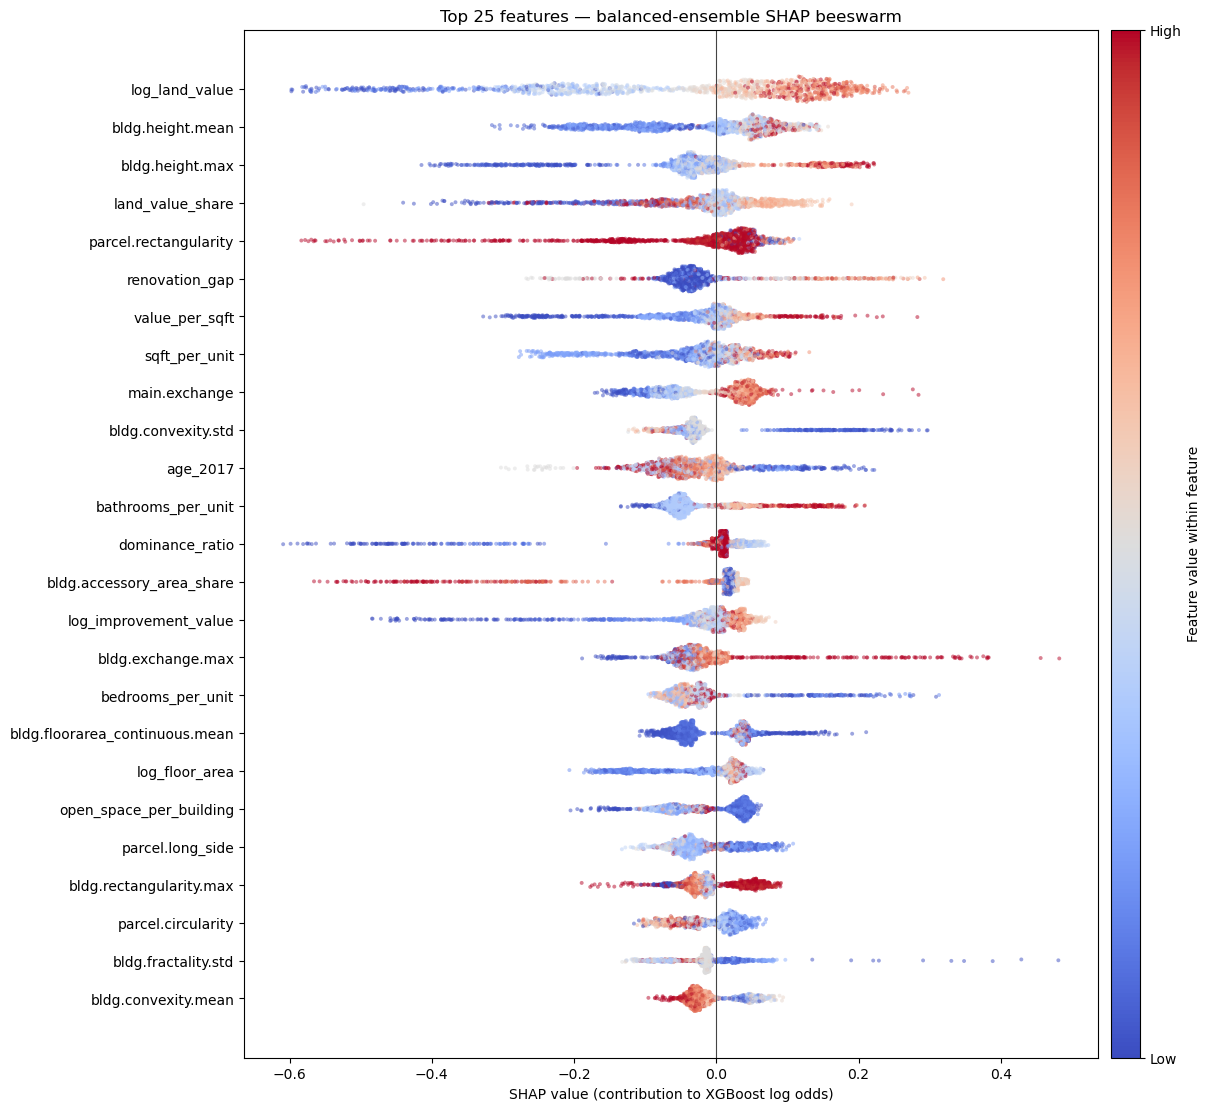

In [4]:
def build_model_matrix(data, numeric_features):
    numeric = (
        data[numeric_features].apply(pd.to_numeric, errors='coerce')
        .replace([np.inf, -np.inf], np.nan).astype('float32')
    )
    use_types = pd.get_dummies(
        data['SpecificUseType'], prefix='use_type', dtype='float32'
    )
    return pd.concat([numeric, use_types], axis=1)

def make_method3_model(seed, training_labels):
    positives = int(np.sum(training_labels == 1))
    negatives = int(np.sum(training_labels == 0))
    return xgb.XGBClassifier(
        n_estimators=400, learning_rate=0.03, max_depth=4,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
        reg_lambda=5.0, max_delta_step=1, tree_method='hist',
        eval_metric='aucpr', n_jobs=-1, random_state=seed,
        scale_pos_weight=negatives / max(positives, 1),
    )

def sample_balanced_fit_rows(data, candidate_rows, seed):
    columns = ['SpecificUseType', 'GEOID_TRACT', 'is_known_udu']
    pool = data.iloc[candidate_rows][columns].copy()
    pool['_row'] = candidate_rows
    positives = pool.loc[pool['is_known_udu']]
    negatives = pool.loc[~pool['is_known_udu']]
    rng = np.random.default_rng(seed)
    selected = [positives['_row'].to_numpy()]
    keys = ['SpecificUseType', 'GEOID_TRACT']
    negative_groups = {
        key: group['_row'].to_numpy()
        for key, group in negatives.groupby(keys, observed=True, sort=False)
    }
    for key, group in positives.groupby(keys, observed=True, sort=False):
        candidates = negative_groups.get(key, np.empty(0, dtype=int))
        sample_size = min(
            len(candidates), NEGATIVE_TO_POSITIVE_RATIO * len(group)
        )
        if sample_size:
            selected.append(rng.choice(candidates, sample_size, replace=False))
    rows = np.concatenate(selected).astype(int, copy=False)
    rng.shuffle(rows)
    return rows

def cross_fitted_scores(data, feature_columns, n_splits=N_SPLITS):
    X = build_model_matrix(data, feature_columns)
    y = data['is_known_udu'].astype(int).to_numpy()
    train_mask = data['method3_in_training_geography'].to_numpy(dtype=bool)
    train_rows = np.flatnonzero(train_mask)
    apply_rows = np.flatnonzero(~train_mask)
    y_train = y[train_rows]
    groups = data.loc[train_mask, 'GEOID_TRACT'].astype(str).to_numpy()
    if y_train.sum() < n_splits:
        raise ValueError('Too few known UDUs in the training geography')

    score_sum = np.zeros(len(data), dtype=float)
    score_count = np.zeros(len(data), dtype=np.int16)
    applied_sum = np.zeros(len(apply_rows), dtype=float)
    model_count = 0
    importance_sum = np.zeros(X.shape[1], dtype=float)
    fold_rows = []
    for repeat in range(N_REPEATS):
        cv = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE + repeat
        )
        for fold, (fit_relative, test_relative) in enumerate(
            cv.split(X.iloc[train_rows], y_train, groups), start=1
        ):
            fit_rows = train_rows[fit_relative]
            test_rows = train_rows[test_relative]
            fold_score_sum = np.zeros(len(test_rows), dtype=float)
            bag_sizes = []
            bag_positive_counts = []
            bag_feature_counts = []
            for bag in range(N_BALANCED_BAGS):
                seed = RANDOM_STATE + repeat * 10_000 + fold * 100 + bag
                balanced_rows = sample_balanced_fit_rows(data, fit_rows, seed)
                model = make_method3_model(seed, y[balanced_rows])
                model.fit(X.iloc[balanced_rows], y[balanced_rows])
                importance_sum += model.feature_importances_
                fold_score_sum += model.predict_proba(X.iloc[test_rows])[:, 1]
                if len(apply_rows):
                    applied_sum += model.predict_proba(X.iloc[apply_rows])[:, 1]
                bag_sizes.append(len(balanced_rows))
                bag_positive_counts.append(int(y[balanced_rows].sum()))
                bag_feature_counts.append(
                    int(np.count_nonzero(model.feature_importances_))
                )
                model_count += 1
            fold_scores = fold_score_sum / N_BALANCED_BAGS
            score_sum[test_rows] += fold_scores
            score_count[test_rows] += 1
            fold_rows.append({
                'repeat': repeat + 1, 'fold': fold,
                'candidate_training_rows': len(fit_rows),
                'balanced_training_rows': int(np.mean(bag_sizes)),
                'balanced_training_udu': int(np.mean(bag_positive_counts)),
                'mean_features_used': float(np.mean(bag_feature_counts)),
                'balanced_unlabeled_per_udu': (
                    (np.mean(bag_sizes) - np.mean(bag_positive_counts))
                    / np.mean(bag_positive_counts)
                ),
                'validation_rows': len(test_rows),
                'validation_udu': int(y[test_rows].sum()),
                'roc_auc': roc_auc_score(y[test_rows], fold_scores),
                'average_precision': average_precision_score(y[test_rows], fold_scores),
            })
    scores = np.full(len(data), np.nan, dtype=float)
    scores[train_rows] = score_sum[train_rows] / score_count[train_rows]
    if len(apply_rows):
        scores[apply_rows] = applied_sum / model_count
    score_method = np.where(train_mask, 'out_of_fold', 'fold_ensemble_application')
    importance = (
        pd.DataFrame({
            'feature': X.columns,
            'mean_xgboost_importance': importance_sum / model_count,
        })
        .sort_values('mean_xgboost_importance', ascending=False)
        .reset_index(drop=True)
    )
    return scores, score_method, pd.DataFrame(fold_rows), importance

method3_scores, method3_score_method, method3_fold_diagnostics, method3_feature_importance = (
    cross_fitted_scores(method3_input, MODEL_FEATURES)
)
method3_input['method3_udu_score'] = method3_scores
method3_input['method3_score_method'] = method3_score_method
def feature_family(feature):
    if feature.startswith(('bldg.', 'main.')):
        return 'building morphology'
    if feature.startswith(('parcel.', 'open_space', 'footprint_')):
        return 'parcel shape and open space'
    if feature in ADMINISTRATIVE_FEATURES:
        return 'administrative and assessor history'
    if feature in TCAC_FEATURES:
        return 'TCAC opportunity context'
    if feature.startswith('use_type_'):
        return 'use type indicators'
    return 'assessor and parcel–building relations'

method3_feature_importance['feature_family'] = (
    method3_feature_importance['feature'].map(feature_family)
)
method3_feature_family_importance = (
    method3_feature_importance.groupby('feature_family', as_index=False)
    ['mean_xgboost_importance'].sum()
    .sort_values('mean_xgboost_importance', ascending=False)
)
display(method3_fold_diagnostics)
display(method3_feature_importance.head(25))
display(
    method3_feature_importance.loc[
        method3_feature_importance['feature_family'].eq(
            'administrative and assessor history'
        )
    ].head(15)
)
display(
    method3_feature_importance.loc[
        method3_feature_importance['feature_family'].eq(
            'TCAC opportunity context'
        )
    ]
)
display(method3_feature_family_importance)
display(pd.Series({
    'mean fold ROC AUC': method3_fold_diagnostics['roc_auc'].mean(),
    'mean fold average precision': method3_fold_diagnostics['average_precision'].mean(),
    'training-pool positive share': method3_input.loc[method3_input['method3_in_training_geography'], 'is_known_udu'].mean(),
    'cross-validation repeats': N_REPEATS,
    'balanced bags per fold': N_BALANCED_BAGS,
    'maximum unlabeled per UDU': NEGATIVE_TO_POSITIVE_RATIO,
    'numeric features': len(MODEL_FEATURES),
    'total model columns': len(method3_feature_importance),
}, name='value').to_frame())

method3_shap_feature_values, method3_shap_values, method3_shap_importance = (
    build_balanced_shap_summary(method3_input, MODEL_FEATURES)
)
display(method3_shap_importance.head(SHAP_TOP_N))
plot_shap_beeswarm(
    method3_shap_feature_values, method3_shap_values,
    method3_shap_importance, top_n=SHAP_TOP_N,
)

## Rank within use type and apply the cutoff

Lower scores indicate parcels least similar to reported UDUs. The initial Boolean selects the bottom 5% within each supported use type and always excludes known UDUs.

In [5]:
def build_method3_features(data, percentile=METHOD3_PERCENTILE):
    result = data[[
        'AIN', 'SpecificUseType', 'is_known_udu',
        'method3_in_training_geography', 'GEOID_TRACT',
        'method3_udu_score', 'method3_score_method',
    ]].copy()
    result['method3_score_pct_rank_by_use_type'] = (
        result.groupby('SpecificUseType')['method3_udu_score']
        .rank(method='average', pct=True)
    )
    result['method3_percentile_cutoff'] = float(percentile)
    result['method3_potential_nonudu'] = (
        result['method3_score_pct_rank_by_use_type'].le(percentile)
        & ~result['is_known_udu']
    )
    return result.sort_values('AIN').reset_index(drop=True)

method3_features = build_method3_features(method3_input)
method3_output = method3_features[['AIN', 'method3_potential_nonudu']].copy()
display(method3_features.groupby('SpecificUseType').agg(
    eligible_ains=('AIN', 'size'),
    known_udu=('is_known_udu', 'sum'),
    potential_nonudu=('method3_potential_nonudu', 'sum'),
).sort_values('eligible_ains', ascending=False))

,eligible_ains,known_udu,potential_nonudu
SpecificUseType,,,
Single Family Residence,430801,10,21540
"Double, Duplex, or Two Units",42861,90,2142
Five or More Units or Apartments (Any Combination),29209,180,1457
Three Units (Any Combination),13648,74,680
Four Units (Any Combination),13396,39,669
Store Combination,5216,16,258


## Diagnostics

These plots compare known UDUs with the unlabeled population. A useful bottom-tail rule should contain very few known UDUs; it is not evidence that every selected parcel is a verified non-UDU.

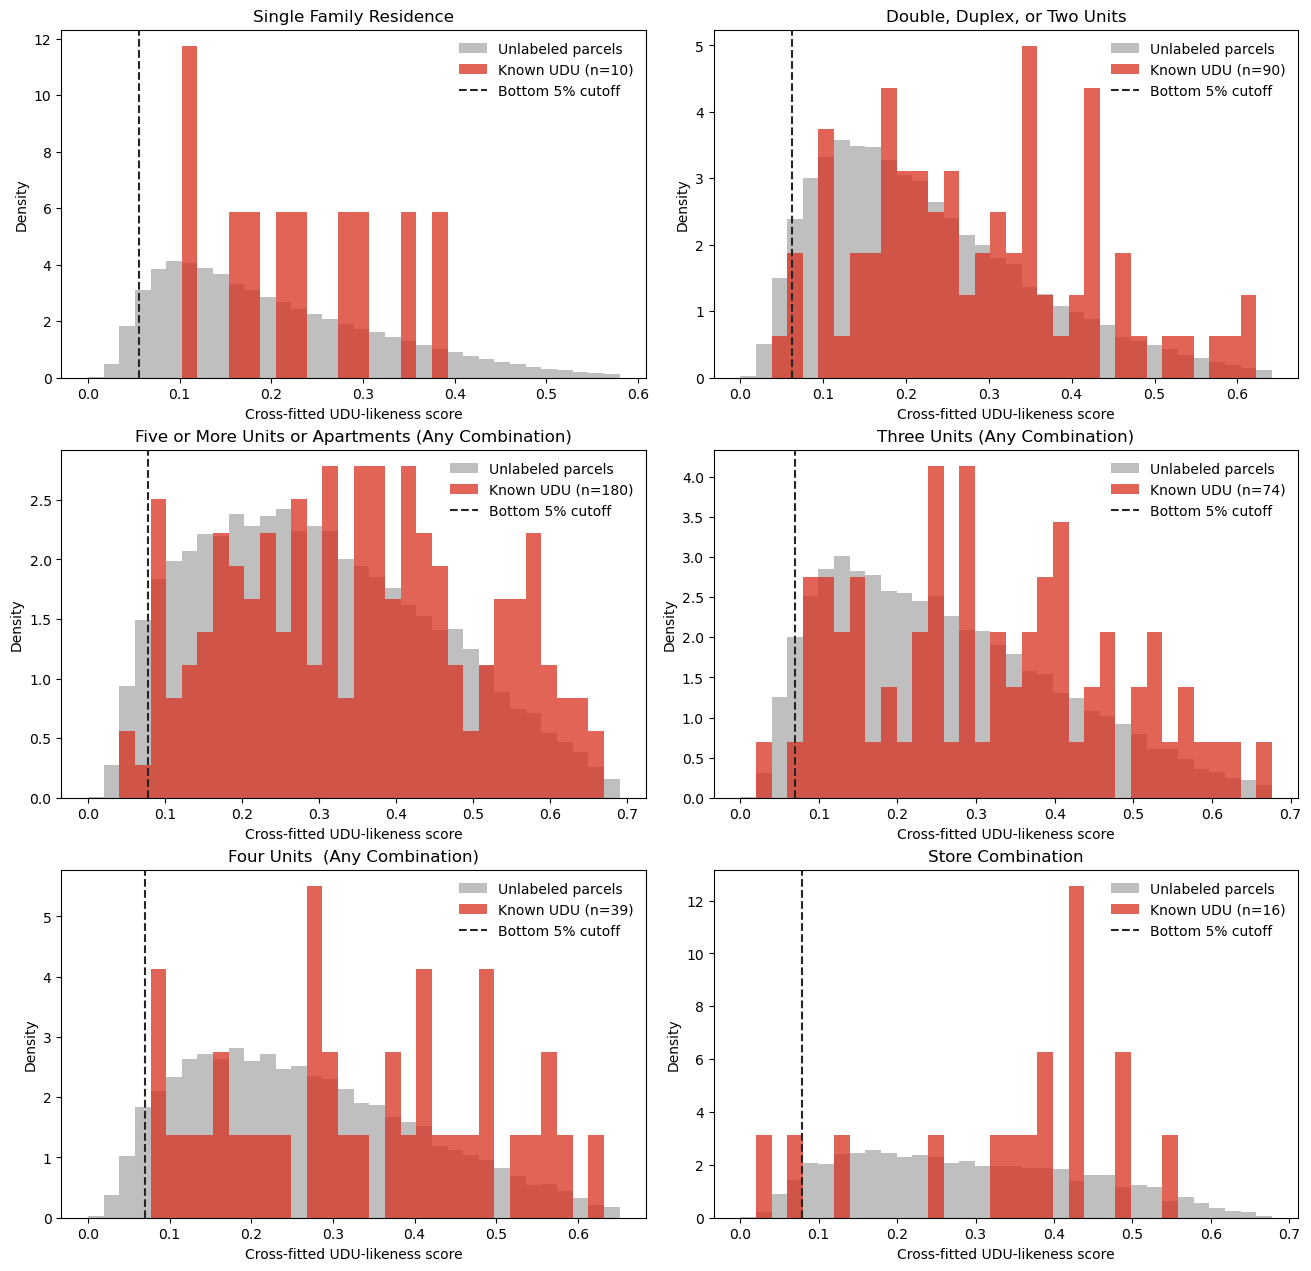

,percentile,selected_ains,known_udu_selected,potential_nonudu_after_excluding_udu
0,0.010,5349,2,5347
1,0.025,13376,4,13372
2,0.050,26754,8,26746
3,0.100,53510,26,53484


In [6]:
use_types = method3_features['SpecificUseType'].value_counts().index.tolist()
ncols = 2
nrows = int(np.ceil(len(use_types) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.2 * nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, use_types):
    group = method3_features.loc[method3_features['SpecificUseType'].eq(use_type)]
    other = group.loc[~group['is_known_udu'], 'method3_udu_score']
    known = group.loc[group['is_known_udu'], 'method3_udu_score']
    bins = np.linspace(0, max(group['method3_udu_score'].quantile(0.995), 1e-6), 35)
    ax.hist(other, bins=bins, density=True, alpha=0.45, color='#737373', label='Unlabeled parcels')
    ax.hist(known, bins=bins, density=True, alpha=0.75, color='#d7301f', label=f'Known UDU (n={len(known):,})')
    cutoff = group['method3_udu_score'].quantile(METHOD3_PERCENTILE)
    ax.axvline(cutoff, color='#252525', linestyle='--', label='Bottom 5% cutoff')
    ax.set_title(use_type, wrap=True)
    ax.set_xlabel('Cross-fitted UDU-likeness score')
    ax.set_ylabel('Density')
    ax.legend(frameon=False)
for ax in axes[len(use_types):]:
    ax.remove()
plt.show()

sensitivity = []
for cutoff in [0.01, 0.025, 0.05, 0.10]:
    selected = method3_features['method3_score_pct_rank_by_use_type'].le(cutoff)
    sensitivity.append({
        'percentile': cutoff, 'selected_ains': int(selected.sum()),
        'known_udu_selected': int((selected & method3_features['is_known_udu']).sum()),
        'potential_nonudu_after_excluding_udu': int((selected & ~method3_features['is_known_udu']).sum()),
    })
display(pd.DataFrame(sensitivity))

## Primary output

In [7]:
display(pd.Series({
    'Output AINs': len(method3_output),
    'Method 3 potential non-UDU AINs': int(method3_output['method3_potential_nonudu'].sum()),
    'Potential non-UDU share': method3_output['method3_potential_nonudu'].mean(),
}, name='value').to_frame())
display(method3_features.head())
display(method3_output.head())

# Deliberately not saved during method development. When finalized:
# output_path = CITY_OUTPUT / 'method3_potential_nonudu_2017.parquet'
# output_path.parent.mkdir(parents=True, exist_ok=True)
# method3_output.to_parquet(output_path, index=False)

,value
Output AINs,535131.00000
Method 3 potential non-UDU AINs,26746.00000
Potential non-UDU share,0.04998


,AIN,SpecificUseType,is_known_udu,method3_in_training_geography,GEOID_TRACT,method3_udu_score,method3_score_method,method3_score_pct_rank_by_use_type,method3_percentile_cutoff,method3_potential_nonudu
0,2004001003,Single Family Residence,False,False,NaN,0.084885,fold_ensemble_application,0.154909,0.05,False
1,2004001004,Single Family Residence,False,False,NaN,0.429744,fold_ensemble_application,0.944081,0.05,False
2,2004001005,Single Family Residence,False,False,NaN,0.348032,fold_ensemble_application,0.863445,0.05,False
3,2004001008,Single Family Residence,False,False,NaN,0.080636,fold_ensemble_application,0.137957,0.05,False
4,2004001009,Single Family Residence,False,False,NaN,0.291334,fold_ensemble_application,0.775950,0.05,False


,AIN,method3_potential_nonudu
0,2004001003,False
1,2004001004,False
2,2004001005,False
3,2004001008,False
4,2004001009,False


## Spatial pattern of the Method 3 score

The left map shows the median `method3_score_pct_rank_by_use_type` of eligible non-UDU AINs. Ranks are uniform within each use type, so 0.5 is the citywide expectation. The colour scale is reversed so that red marks areas that lean least UDU-like, matching the Method 2 maps. Training-geography rows carry out-of-fold scores, and all other rows carry fold-ensemble scores, so apparent boundaries at the training-tract edges may reflect that split. The right map shows the share of eligible AINs flagged `method3_potential_nonudu` (the bottom `METHOD3_PERCENTILE` within each use type).

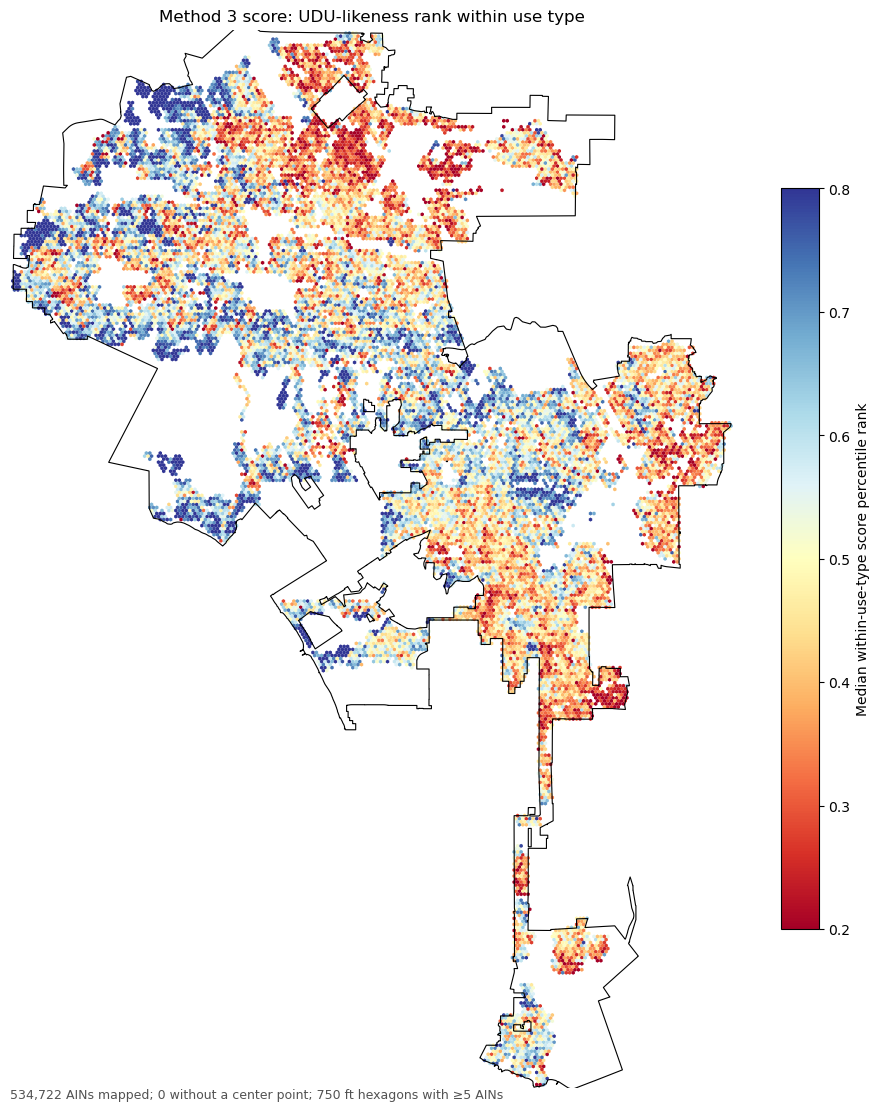

In [8]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import plot_ain_hexbin

import geopandas as gpd
from src.viz import AIN_POINT_CRS


unlabeled = method3_features.loc[~method3_features['is_known_udu']]

fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)
plot_ain_hexbin(
    unlabeled, 'method3_score_pct_rank_by_use_type', ax=ax, #axes[0],
    cmap='RdYlBu', vmin=0.2, vmax=0.8, hex_width_ft=750,
    title='Method 3 score: UDU-likeness rank within use type',
    colorbar_label='Median within-use-type score percentile rank',
)
# GeoJSON is WGS84; the hexbins are in EPSG:2229 feet.
lac = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
lac.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()

## Regularized variant: trimming the feature set

The baseline model offers 149 columns (143 numeric features and 6 use-type indicators) to about 340 known UDUs per training fold, which is fewer than three positives per feature. Each bagged model splits on roughly 130 of those columns (`mean_features_used` above), and gain is spread almost evenly: the top feature carries about 1% of total gain, against 0.7% if every column were used equally. That pattern raises the question of whether many splits are fitting noise.

The variant keeps the baseline's tract-grouped folds, balanced bags and scoring rules, so the two models can be compared fold by fold. By default it applies two layers:

1. **Label-free redundancy pruning.** Constant features are dropped, as is any feature whose |Spearman ρ| with an earlier feature in `MODEL_FEATURES` is at least `REG_CORRELATION_THRESHOLD`. Many building-shape summaries duplicate base features on single-building parcels. No labels are used, so this step cannot leak into the evaluation.
2. **Stronger tree regularization at the baseline's 400 trees.** Depth 3, minimum child weight 10, a split-loss penalty (`gamma` 1), L1 (`reg_alpha` 1) and L2 (`reg_lambda` 10) penalties on leaf weights, and row and column subsampling of 0.7 and 0.5. XGBoost's L1 and L2 terms shrink leaf weights; they do not remove features on their own.

Two further steps are available but off by default, because both lowered out-of-fold ROC AUC in an ablation on the same folds:

- **Early stopping** on a tract-grouped inner split (`REG_EARLY_STOPPING_ROUNDS`). With about 70 validation UDUs it stopped after roughly 70 trees.
- **Nested shadow-feature selection** (`REG_SHADOW_SELECTION`). Inside each outer fold, a feature is kept only if its gain beats permuted copies of every feature in at least `REG_MIN_BAG_HITS` bags. It kept 2–7 features.

Ablation on the 29 September 2026 tile outputs (15 paired folds; the baseline uses all 143 features):

| configuration | features | mean fold ROC AUC | paired change | folds better |
|---|---|---|---|---|
| baseline | 143 | 0.719 | — | — |
| baseline hyperparameters, pruned | 105 | 0.724 | +0.005 | 12 of 15 |
| milder penalties, pruned | 105 | 0.717 | −0.002 | 7 of 15 |
| **stronger penalties, pruned (default)** | 105 | 0.718 | −0.001 | 9 of 15 |
| stronger penalties, pruned, early stopping | 105 | 0.695 | −0.023 | 3 of 15 |
| milder penalties, shadow selection at the 0.9 quantile | ~6.5 | 0.655 | −0.064 | 0 of 15 |
| milder penalties, shadow selection at the strongest shadow | ~2 | 0.611 | −0.108 | 0 of 15 |

The signal is spread across many weak, correlated features, so aggressive feature selection discards real information and trimming is best limited to duplicates. The stronger penalties leave accuracy unchanged. They are the default because they are the most regularized configuration within one standard error of the best, the usual tie-break; pruning alone with the baseline hyperparameters scored marginally higher.

The primary output above is unchanged. The variant's results are stored in `method3_reg_features` and `method3_reg_output`.

In [9]:
# Defaults follow the ablation in the markdown above: redundancy pruning plus
# stronger leaf and split penalties at the baseline's fixed 400 trees.
REG_CORRELATION_THRESHOLD = 0.95
REG_CORRELATION_SAMPLE = 50_000
REG_PARAMS = {
    'n_estimators': 400,
    'learning_rate': 0.03,
    'max_depth': 3,
    'min_child_weight': 10,
    'gamma': 1.0,
    'reg_alpha': 1.0,
    'reg_lambda': 10.0,
    'subsample': 0.7,
    'colsample_bytree': 0.5,
    'max_delta_step': 1,
}
# Optional steps, off by default because both lowered out-of-fold ROC AUC.
REG_EARLY_STOPPING_ROUNDS = None  # e.g. 100 to stop on a tract-grouped inner split
REG_INNER_VALIDATION_SPLITS = 5
REG_SHADOW_SELECTION = False
REG_SHADOW_QUANTILE = 1.0
REG_MIN_BAG_HITS = 3  # of N_BALANCED_BAGS
REG_MIN_SELECTED_FEATURES = 5

def prune_redundant_features(data, feature_columns):
    """Drop constant features and near-duplicates without using labels.

    Features are visited in ``feature_columns`` order, so a building-shape or
    history feature is dropped in favour of an earlier base feature it
    duplicates. Spearman correlation is the Pearson correlation of ranks on a
    sample of the training geography.
    """
    rows = data.loc[data['method3_in_training_geography'], feature_columns]
    if len(rows) > REG_CORRELATION_SAMPLE:
        rows = rows.sample(REG_CORRELATION_SAMPLE, random_state=RANDOM_STATE)
    values = (
        rows.apply(pd.to_numeric, errors='coerce')
        .replace([np.inf, -np.inf], np.nan)
    )
    constant = [
        column for column in feature_columns
        if values[column].nunique(dropna=True) <= 1
    ]
    correlation = values.drop(columns=constant).rank().corr().abs()
    kept = []
    dropped = [
        {'feature': column, 'reason': 'constant', 'kept_partner': None, 'abs_spearman': np.nan}
        for column in constant
    ]
    for feature in correlation.columns:
        partners = correlation.loc[feature, kept]
        partners = partners[partners.ge(REG_CORRELATION_THRESHOLD)]
        if partners.empty:
            kept.append(feature)
        else:
            dropped.append({
                'feature': feature, 'reason': 'redundant',
                'kept_partner': partners.idxmax(),
                'abs_spearman': float(partners.max()),
            })
    return kept, pd.DataFrame(
        dropped, columns=['feature', 'reason', 'kept_partner', 'abs_spearman']
    )

REG_CANDIDATE_FEATURES, reg_pruned_features = prune_redundant_features(
    method3_input, MODEL_FEATURES
)
display(pd.Series({
    'baseline numeric features': len(MODEL_FEATURES),
    'dropped as constant': int(reg_pruned_features['reason'].eq('constant').sum()),
    'dropped as redundant': int(reg_pruned_features['reason'].eq('redundant').sum()),
    'candidate features after pruning': len(REG_CANDIDATE_FEATURES),
}, name='features').to_frame())
display(reg_pruned_features.round(3))

,features
baseline numeric features,138
dropped as constant,1
dropped as redundant,37
candidate features after pruning,100


,feature,reason,kept_partner,abs_spearman
0,assessor.building_records,constant,NaN,NaN
1,floor_residual_fraction,redundant,comparison.floor_area_ratio_continuous,1.000
2,parcel.squareness,redundant,parcel.circularity,1.000
3,open_space_share,redundant,snapshot.coverage,1.000
4,bldg.height.max,redundant,mean_building_height,0.970
5,bldg.area.mean,redundant,footprint_per_building,1.000
6,bldg.area.sum,redundant,log_footprint_area,1.000
7,bldg.length.mean,redundant,footprint_per_building,0.970
8,bldg.length.min,redundant,bldg.area.min,0.992
9,bldg.convexity.mean,redundant,bldg.rectangularity.mean,0.968


In [10]:
def make_regularized_model(seed, training_labels):
    positives = int(np.sum(training_labels == 1))
    negatives = int(np.sum(training_labels == 0))
    return xgb.XGBClassifier(
        **REG_PARAMS, early_stopping_rounds=REG_EARLY_STOPPING_ROUNDS,
        tree_method='hist', eval_metric='auc', n_jobs=-1,
        random_state=seed, scale_pos_weight=negatives / max(positives, 1),
    )

def fit_regularized(X, y, groups, seed):
    """Fit one balanced bag, early-stopping on a tract-grouped split if enabled.

    ROC AUC is the stopping metric because it ignores the class weighting and
    is steadier than average precision with ~70 validation UDUs.
    """
    if REG_EARLY_STOPPING_ROUNDS is None:
        model = make_regularized_model(seed, y)
        model.fit(X, y)
        return model
    splitter = StratifiedGroupKFold(
        n_splits=REG_INNER_VALIDATION_SPLITS, shuffle=True, random_state=seed
    )
    fit_rows, stop_rows = next(splitter.split(X, y, groups))
    model = make_regularized_model(seed, y[fit_rows])
    model.fit(
        X.iloc[fit_rows], y[fit_rows],
        eval_set=[(X.iloc[stop_rows], y[stop_rows])], verbose=False,
    )
    return model

def kept_trees(model):
    """Trees used for prediction: the early-stopping best, or all of them."""
    if REG_EARLY_STOPPING_ROUNDS is None:
        return model.get_booster().num_boosted_rounds()
    return model.best_iteration + 1

def total_gain(model, columns):
    """Total gain per column over the trees used for prediction."""
    booster = model.get_booster()[0:kept_trees(model)]
    gain = booster.get_score(importance_type='total_gain')
    return pd.Series(gain, dtype='float64').reindex(columns, fill_value=0.0)

def predict_regularized(model, X):
    return model.predict_proba(X, iteration_range=(0, kept_trees(model)))[:, 1]

def select_against_shadows(X, y, groups, bags, seeds, candidate_features, fixed_columns):
    """Keep features whose gain beats permuted copies in enough bags."""
    hits = pd.Series(0, index=candidate_features, dtype='int64')
    mean_gain = pd.Series(0.0, index=candidate_features)
    for seed, rows in zip(seeds, bags):
        rng = np.random.default_rng(seed + 50_000)
        real = X.iloc[rows][candidate_features].reset_index(drop=True)
        shadow = pd.DataFrame({
            f'shadow__{column}': rng.permutation(real[column].to_numpy())
            for column in candidate_features
        })
        bag_X = pd.concat(
            [real, X.iloc[rows][fixed_columns].reset_index(drop=True), shadow],
            axis=1,
        )
        model = fit_regularized(bag_X, y[rows], groups[rows], seed)
        gain = total_gain(model, bag_X.columns)
        threshold = gain[shadow.columns].quantile(REG_SHADOW_QUANTILE)
        hits += gain[candidate_features].gt(threshold).astype('int64')
        mean_gain += gain[candidate_features] / len(bags)
    selected = hits.index[hits.ge(REG_MIN_BAG_HITS)].tolist()
    if len(selected) < REG_MIN_SELECTED_FEATURES:
        selected = mean_gain.nlargest(REG_MIN_SELECTED_FEATURES).index.tolist()
    return selected

def regularized_cross_fitted_scores(data, candidate_features, n_splits=N_SPLITS):
    X = build_model_matrix(data, candidate_features)
    use_type_columns = [column for column in X.columns if column.startswith('use_type_')]
    y = data['is_known_udu'].astype(int).to_numpy()
    tracts = data['GEOID_TRACT'].astype(str).to_numpy()
    train_mask = data['method3_in_training_geography'].to_numpy(dtype=bool)
    train_rows = np.flatnonzero(train_mask)
    apply_rows = np.flatnonzero(~train_mask)
    y_train = y[train_rows]

    score_sum = np.zeros(len(data), dtype=float)
    score_count = np.zeros(len(data), dtype=np.int16)
    applied_sum = np.zeros(len(apply_rows), dtype=float)
    model_count = 0
    selection_counts = pd.Series(0, index=candidate_features, dtype='int64')
    fold_rows = []
    for repeat in range(N_REPEATS):
        # Same splits as the baseline, so fold results pair up exactly.
        cv = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE + repeat
        )
        for fold, (fit_relative, test_relative) in enumerate(
            cv.split(X.iloc[train_rows], y_train, tracts[train_rows]), start=1
        ):
            fit_rows = train_rows[fit_relative]
            test_rows = train_rows[test_relative]
            seeds = [
                RANDOM_STATE + repeat * 10_000 + fold * 100 + bag
                for bag in range(N_BALANCED_BAGS)
            ]
            bags = [sample_balanced_fit_rows(data, fit_rows, seed) for seed in seeds]
            selected = (
                select_against_shadows(
                    X, y, tracts, bags, seeds, candidate_features, use_type_columns
                )
                if REG_SHADOW_SELECTION else list(candidate_features)
            )
            selection_counts[selected] += 1
            columns = selected + use_type_columns
            test_X = X.iloc[test_rows][columns]
            apply_X = X.iloc[apply_rows][columns]

            fold_score_sum = np.zeros(len(test_rows), dtype=float)
            best_iterations, features_used = [], []
            for seed, rows in zip(seeds, bags):
                model = fit_regularized(
                    X.iloc[rows][columns].reset_index(drop=True),
                    y[rows], tracts[rows], seed,
                )
                fold_score_sum += predict_regularized(model, test_X)
                if len(apply_rows):
                    applied_sum += predict_regularized(model, apply_X)
                best_iterations.append(kept_trees(model))
                features_used.append(int(total_gain(model, columns).gt(0).sum()))
                model_count += 1
            fold_scores = fold_score_sum / N_BALANCED_BAGS
            score_sum[test_rows] += fold_scores
            score_count[test_rows] += 1
            fold_rows.append({
                'repeat': repeat + 1, 'fold': fold,
                'selected_features': len(selected),
                'mean_features_used': float(np.mean(features_used)),
                'mean_trees': float(np.mean(best_iterations)),
                'validation_rows': len(test_rows),
                'validation_udu': int(y[test_rows].sum()),
                'roc_auc': roc_auc_score(y[test_rows], fold_scores),
                'average_precision': average_precision_score(y[test_rows], fold_scores),
            })
    scores = np.full(len(data), np.nan, dtype=float)
    scores[train_rows] = score_sum[train_rows] / score_count[train_rows]
    if len(apply_rows):
        scores[apply_rows] = applied_sum / model_count
    score_method = np.where(train_mask, 'out_of_fold', 'fold_ensemble_application')
    total_folds = N_REPEATS * n_splits
    selection = (
        selection_counts.rename('folds_selected').rename_axis('feature').reset_index()
        .assign(
            share_of_folds=lambda frame: frame['folds_selected'] / total_folds,
            feature_family=lambda frame: frame['feature'].map(feature_family),
        )
        .sort_values(['folds_selected', 'feature'], ascending=[False, True])
        .reset_index(drop=True)
    )
    return scores, score_method, pd.DataFrame(fold_rows), selection

(
    method3_reg_scores, method3_reg_score_method,
    method3_reg_fold_diagnostics, method3_reg_selection,
) = regularized_cross_fitted_scores(method3_input, REG_CANDIDATE_FEATURES)
display(method3_reg_fold_diagnostics)
display(method3_reg_selection.loc[method3_reg_selection['folds_selected'].gt(0)])

,repeat,fold,selected_features,mean_features_used,mean_trees,validation_rows,validation_udu,roc_auc,average_precision
0,1,1,100,89.4,400.0,25426,82,0.689869,0.008848
1,1,2,100,91.4,400.0,25637,81,0.695263,0.007647
2,1,3,100,87.0,400.0,25341,82,0.702860,0.008149
3,1,4,100,87.2,400.0,25440,82,0.670044,0.007558
4,1,5,100,90.0,400.0,25857,81,0.716543,0.008861
5,2,1,100,89.6,400.0,25320,82,0.715905,0.009378
6,2,2,100,90.6,400.0,25775,81,0.745455,0.008062
7,2,3,100,89.0,400.0,25508,82,0.760650,0.010858
8,2,4,100,86.4,400.0,25555,81,0.606404,0.005157
9,2,5,100,87.8,400.0,25543,82,0.716626,0.015194


,feature,folds_selected,share_of_folds,feature_family
0,age_2017,15,1.0,assessor and parcel–building relations
1,assessor.bathrooms,15,1.0,assessor and parcel–building relations
2,assessor.bedrooms,15,1.0,assessor and parcel–building relations
3,assessor.units,15,1.0,assessor and parcel–building relations
4,assessor_building_record_change_2010_2016,15,1.0,administrative and assessor history
...,...,...,...,...
95,tcac_opp_index,15,1.0,TCAC opportunity context
96,value_per_sqft,15,1.0,assessor and parcel–building relations
97,zoning_case_any,15,1.0,administrative and assessor history
98,zoning_recent_count,15,1.0,administrative and assessor history


,baseline,regularized
numeric features offered,138.0000,100.0000
median features selected per fold,138.0000,100.0000
mean columns used per model,126.3333,89.0933
mean fold ROC AUC,0.6947,0.6996
SD of fold ROC AUC,0.0365,0.0370
mean fold average precision,0.0093,0.0089
known UDU in bottom 5%,8.0000,8.0000
known UDU share in bottom 5%,0.0196,0.0196


,value
mean paired ROC AUC change (regularized − baseline),0.004915
SD of paired ROC AUC change,0.006704
folds where regularized AUC is higher,11 of 15
rank correlation of within-use-type scores,0.972769
AINs flagged by both,21202
flag overlap (Jaccard),0.656612


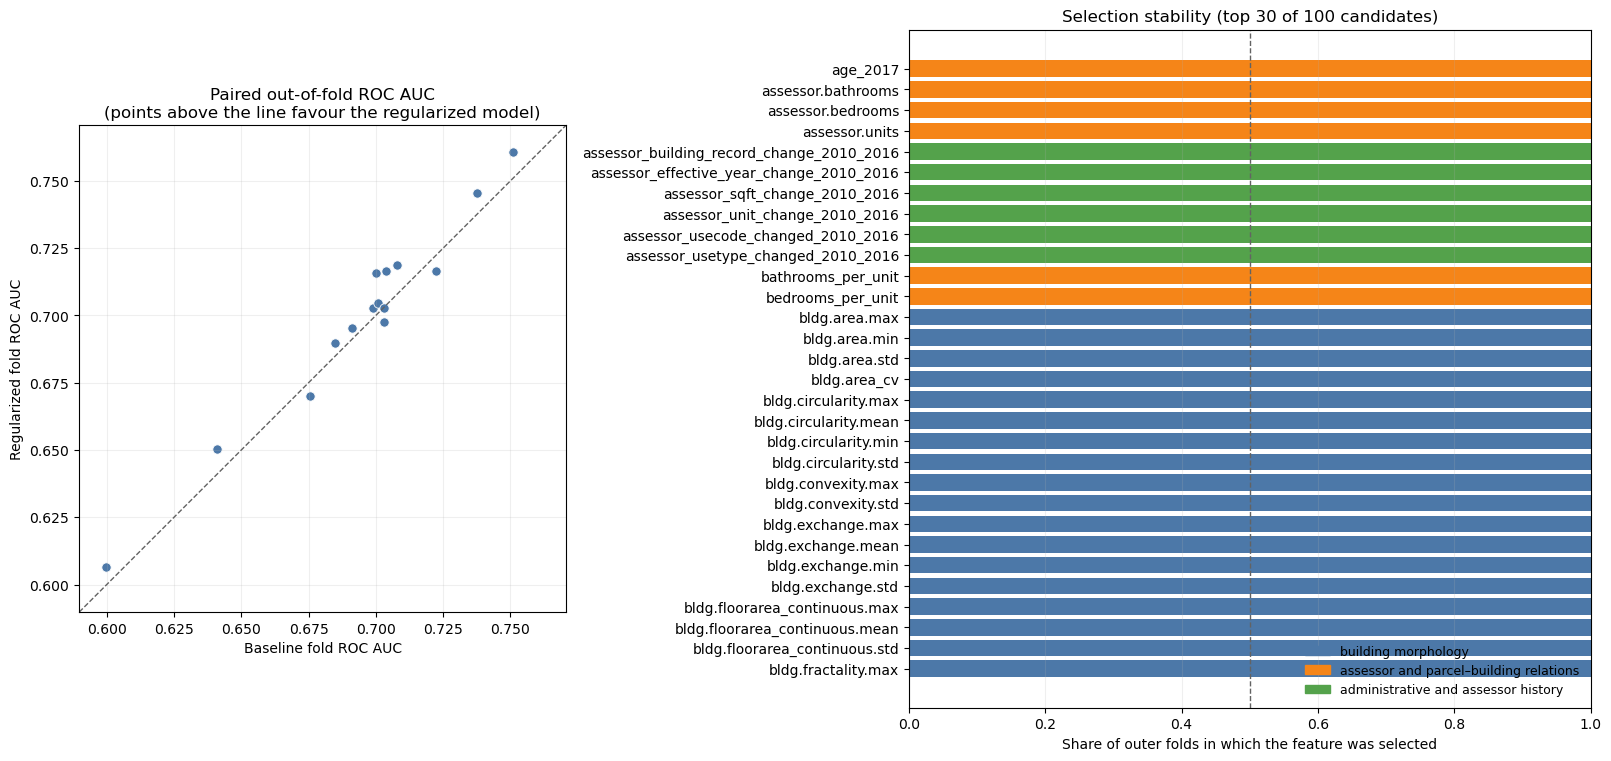

In [11]:
method3_reg_features = build_method3_features(method3_input.assign(
    method3_udu_score=method3_reg_scores,
    method3_score_method=method3_reg_score_method,
))
method3_reg_output = method3_reg_features[['AIN', 'method3_potential_nonudu']].copy()

def bottom_tail_known_udu(features):
    known = features.loc[features['is_known_udu'], 'method3_score_pct_rank_by_use_type']
    return int(known.le(METHOD3_PERCENTILE).sum()), float(known.le(METHOD3_PERCENTILE).mean())

paired_folds = method3_fold_diagnostics[
    ['repeat', 'fold', 'roc_auc', 'average_precision']
].merge(
    method3_reg_fold_diagnostics[['repeat', 'fold', 'roc_auc', 'average_precision']],
    on=['repeat', 'fold'], suffixes=('_baseline', '_regularized'),
    validate='one_to_one',
)
auc_difference = paired_folds['roc_auc_regularized'] - paired_folds['roc_auc_baseline']
both_scores = method3_features[
    ['AIN', 'SpecificUseType', 'method3_score_pct_rank_by_use_type', 'method3_potential_nonudu']
].merge(
    method3_reg_features[
        ['AIN', 'method3_score_pct_rank_by_use_type', 'method3_potential_nonudu']
    ],
    on='AIN', suffixes=('_baseline', '_regularized'), validate='one_to_one',
)
flag_baseline = both_scores['method3_potential_nonudu_baseline']
flag_regularized = both_scores['method3_potential_nonudu_regularized']
baseline_tail = bottom_tail_known_udu(method3_features)
regularized_tail = bottom_tail_known_udu(method3_reg_features)

display(pd.DataFrame({
    'baseline': {
        'numeric features offered': len(MODEL_FEATURES),
        'median features selected per fold': len(MODEL_FEATURES),
        'mean columns used per model': method3_fold_diagnostics['mean_features_used'].mean(),
        'mean fold ROC AUC': method3_fold_diagnostics['roc_auc'].mean(),
        'SD of fold ROC AUC': method3_fold_diagnostics['roc_auc'].std(),
        'mean fold average precision': method3_fold_diagnostics['average_precision'].mean(),
        f'known UDU in bottom {METHOD3_PERCENTILE:.0%}': baseline_tail[0],
        f'known UDU share in bottom {METHOD3_PERCENTILE:.0%}': baseline_tail[1],
    },
    'regularized': {
        'numeric features offered': len(REG_CANDIDATE_FEATURES),
        'median features selected per fold': method3_reg_fold_diagnostics['selected_features'].median(),
        'mean columns used per model': method3_reg_fold_diagnostics['mean_features_used'].mean(),
        'mean fold ROC AUC': method3_reg_fold_diagnostics['roc_auc'].mean(),
        'SD of fold ROC AUC': method3_reg_fold_diagnostics['roc_auc'].std(),
        'mean fold average precision': method3_reg_fold_diagnostics['average_precision'].mean(),
        f'known UDU in bottom {METHOD3_PERCENTILE:.0%}': regularized_tail[0],
        f'known UDU share in bottom {METHOD3_PERCENTILE:.0%}': regularized_tail[1],
    },
}).round(4))
display(pd.Series({
    'mean paired ROC AUC change (regularized − baseline)': auc_difference.mean(),
    'SD of paired ROC AUC change': auc_difference.std(),
    'folds where regularized AUC is higher': f'{int(auc_difference.gt(0).sum())} of {len(auc_difference)}',
    'rank correlation of within-use-type scores': both_scores[
        'method3_score_pct_rank_by_use_type_baseline'
    ].corr(both_scores['method3_score_pct_rank_by_use_type_regularized'], method='spearman'),
    'AINs flagged by both': int((flag_baseline & flag_regularized).sum()),
    'flag overlap (Jaccard)': (flag_baseline & flag_regularized).sum()
        / (flag_baseline | flag_regularized).sum(),
}, name='value').to_frame())

family_colors = {
    'building morphology': '#4c78a8',
    'assessor and parcel–building relations': '#f58518',
    'administrative and assessor history': '#54a24b',
    'parcel shape and open space': '#b279a2',
    'TCAC opportunity context': '#e45756',
    'use type indicators': '#9d755d',
}
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7.5), constrained_layout=True,
    gridspec_kw={'width_ratios': [1, 1.4]},
)
ax = axes[0]
ax.scatter(
    paired_folds['roc_auc_baseline'], paired_folds['roc_auc_regularized'],
    s=45, color='#4c78a8', edgecolor='white', linewidth=0.6,
)
limits = [
    paired_folds[['roc_auc_baseline', 'roc_auc_regularized']].min().min() - 0.01,
    paired_folds[['roc_auc_baseline', 'roc_auc_regularized']].max().max() + 0.01,
]
ax.plot(limits, limits, '--', color='#636363', linewidth=1)
ax.set(
    xlim=limits, ylim=limits, aspect='equal',
    xlabel='Baseline fold ROC AUC', ylabel='Regularized fold ROC AUC',
    title='Paired out-of-fold ROC AUC\n(points above the line favour the regularized model)',
)
ax.grid(alpha=0.2)

ax = axes[1]
shown = method3_reg_selection.loc[method3_reg_selection['folds_selected'].gt(0)].head(30)
ax.barh(
    shown['feature'][::-1], shown['share_of_folds'][::-1],
    color=shown['feature_family'][::-1].map(family_colors),
)
ax.axvline(0.5, color='#636363', linestyle='--', linewidth=1)
ax.set(
    xlim=(0, 1), xlabel='Share of outer folds in which the feature was selected',
    title=f'Selection stability (top {len(shown)} of {len(REG_CANDIDATE_FEATURES)} candidates)',
)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=color, label=family)
        for family, color in family_colors.items()
        if family in set(shown['feature_family'])
    ],
    frameon=False, loc='lower right', fontsize=9,
)
ax.grid(axis='x', alpha=0.2)
plt.show()

### Reading the comparison

- **Paired fold AUC.** Both models use identical tract-grouped folds, so compare them fold by fold rather than by the pooled mean. If the regularized model matches the baseline within the fold-to-fold spread while using far fewer columns, the extra baseline features were not adding out-of-sample signal, and the simpler model is preferable.
- **Bottom-tail known-UDU share.** This measures what Method 3 is actually used for. Under random ranking, about `METHOD3_PERCENTILE` of known UDUs would land in the flagged tail; lower is better. Nearly all known UDUs are in the training geography, so their scores are out-of-fold.
- **Selection stability.** Features selected in most folds form a stable core. Features selected in only a few folds are unstable and are the first to distrust in the baseline's importance tables.
- **TCAC caveat.** Unlabeled parcels are sampled from the same tract and use type as each UDU, so tract-level context such as the TCAC scores hardly varies within a matched set. Any signal those features carry comes from differences in UDU density between tracts, which is the reporting geography the model is meant to avoid. Shadow selection cannot detect this, so check whether the TCAC features survive selection.
- **Adopting the variant.** To make it the primary output, set `method3_output = method3_reg_output` and `method3_features = method3_reg_features` before the output and map cells. The tuning knobs are `REG_PARAMS`, `REG_SHADOW_QUANTILE` (lower keeps more features) and `REG_MIN_BAG_HITS`.

## Land-value-matched variant

The tract-matched design above learns only what separates a reported UDU from neighbours in its own tract, then ranks parcels citywide. Three quarters of parcels lie outside the UDU tracts and receive extrapolated scores, and the resulting ranking closely tracks land value. This variant matches on land value instead of location:

- **Matching strata.** Each known UDU is paired with up to `NEGATIVE_TO_POSITIVE_RATIO` unlabeled parcels of the same use type and the same land-value band, drawn from anywhere in the city. Bands are `LV_BANDS` quantiles of 2016 assessor land value per square foot of lot, computed within use type. Value per square foot measures how valuable the location is while leaving lot size free as a parcel feature. Parcels without a positive land value form their own band (0).
- **Spatial folds.** Every eligible parcel is in the training pool, so cross-validation is grouped by `LV_GROUP_CELL_FT` grid squares rather than legacy tracts. Every parcel receives an out-of-fold score; none is extrapolated.
- **Features.** The baseline XGBoost settings and features, without the TCAC opportunity scores. Those are tract-level context; with controls drawn citywide they would mostly learn where reports cluster.
- **Flag.** The bottom `METHOD3_PERCENTILE` within each use type × land-value band, the same strata the model was trained to separate. Ranking citywide would bring the land-value gradient back through value-related features.

Controls are no longer drawn from the same neighbourhood as each UDU, so the model can learn geographic patterns beyond land value, including where reports are more common. The diagnostics below check within-band discrimination, within-tract discrimination and the remaining correlation with land value.

In [12]:
from src.viz import load_ain_points

LV_BANDS = 10
LV_GROUP_CELL_FT = 5280  # 1-mile squares as cross-validation groups
LV_MATCH_KEYS = ['SpecificUseType', 'method3_lv_band']
LV_MODEL_FEATURES = [feature for feature in MODEL_FEATURES if feature not in TCAC_FEATURES]

land_value_per_sqft = safe_divide(
    method3_input['roll_landvalue_2016'], method3_input['parcel.area']
).where(lambda values: values.gt(0))
method3_input['method3_lv_value_rank'] = (
    land_value_per_sqft.groupby(method3_input['SpecificUseType']).rank(pct=True)
)
method3_input['method3_lv_band'] = (
    np.ceil(method3_input['method3_lv_value_rank'] * LV_BANDS).fillna(0).astype(int)
)

lv_points = method3_input[['AIN']].merge(
    load_ain_points(), on='AIN', how='left', validate='one_to_one'
)
lv_groups = (
    np.floor(lv_points['x'] / LV_GROUP_CELL_FT).astype('Int64').astype('string')
    + ':' + np.floor(lv_points['y'] / LV_GROUP_CELL_FT).astype('Int64').astype('string')
).fillna('no_point').to_numpy()

lv_strata = method3_input.groupby(LV_MATCH_KEYS).agg(
    parcels=('AIN', 'size'), known_udu=('is_known_udu', 'sum'),
)
display(pd.Series({
    'eligible AINs in the training pool': len(method3_input),
    'known UDUs': int(method3_input['is_known_udu'].sum()),
    'AINs without a positive land value (band 0)': int(method3_input['method3_lv_band'].eq(0).sum()),
    'use type × band strata': len(lv_strata),
    'strata containing a known UDU': int(lv_strata['known_udu'].gt(0).sum()),
    'strata with fewer than 20 controls per UDU': int((
        lv_strata['known_udu'].gt(0)
        & (lv_strata['parcels'] - lv_strata['known_udu'])
        .lt(NEGATIVE_TO_POSITIVE_RATIO * lv_strata['known_udu'])
    ).sum()),
    'cross-validation groups': len(set(lv_groups)),
    'model features (TCAC removed)': len(LV_MODEL_FEATURES),
}, name='value').to_frame())
display(
    method3_input.loc[method3_input['is_known_udu']]
    .groupby('method3_lv_band').size().rename('known UDUs').to_frame().T
)

,value
eligible AINs in the training pool,535131
known UDUs,409
AINs without a positive land value (band 0),320
use type × band strata,66
strata containing a known UDU,56
strata with fewer than 20 controls per UDU,0
cross-validation groups,511
model features (TCAC removed),133


method3_lv_band,1,2,3,4,5,6,7,8,9,10
known UDUs,22,26,28,38,36,38,39,53,54,75


In [13]:
def sample_matched_bags(data, fit_rows, seeds, keys):
    """Balanced bags: every known UDU plus matched controls from its stratum."""
    pool = data.iloc[fit_rows][[*keys, 'is_known_udu']].reset_index(drop=True)
    pool['_row'] = fit_rows
    positive_groups = {
        key: group['_row'].to_numpy()
        for key, group in pool.loc[pool['is_known_udu']].groupby(keys, observed=True, sort=False)
    }
    negative_groups = {
        key: group['_row'].to_numpy()
        for key, group in pool.loc[~pool['is_known_udu']].groupby(keys, observed=True, sort=False)
    }
    bags = []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        selected = list(positive_groups.values())
        for key, positives in positive_groups.items():
            candidates = negative_groups.get(key, np.empty(0, dtype=int))
            size = min(len(candidates), NEGATIVE_TO_POSITIVE_RATIO * len(positives))
            if size:
                selected.append(rng.choice(candidates, size, replace=False))
        rows = np.concatenate(selected).astype(int, copy=False)
        rng.shuffle(rows)
        bags.append(rows)
    return bags

def within_group_auc(frame, score_column, keys):
    """ROC AUC after ranking scores within groups that contain a known UDU."""
    has_udu = frame.groupby(keys)['is_known_udu'].transform('sum').gt(0)
    subset = frame.loc[has_udu]
    ranks = subset.groupby(keys)[score_column].rank(pct=True)
    return roc_auc_score(subset['is_known_udu'], ranks)

def landvalue_cross_fitted_scores(data, feature_columns, groups, n_splits=N_SPLITS):
    X = build_model_matrix(data, feature_columns)
    y = data['is_known_udu'].astype(int).to_numpy()
    score_sum = np.zeros(len(data), dtype=float)
    score_count = np.zeros(len(data), dtype=np.int16)
    fold_rows = []
    for repeat in range(N_REPEATS):
        cv = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE + repeat
        )
        for fold, (fit_rows, test_rows) in enumerate(cv.split(X, y, groups), start=1):
            seeds = [
                RANDOM_STATE + 200_000 + repeat * 10_000 + fold * 100 + bag
                for bag in range(N_BALANCED_BAGS)
            ]
            bags = sample_matched_bags(data, fit_rows, seeds, LV_MATCH_KEYS)
            test_X = X.iloc[test_rows]
            fold_scores = np.zeros(len(test_rows), dtype=float)
            for seed, rows in zip(seeds, bags):
                model = make_method3_model(seed, y[rows])
                model.fit(X.iloc[rows], y[rows])
                fold_scores += model.predict_proba(test_X)[:, 1]
            fold_scores /= N_BALANCED_BAGS
            score_sum[test_rows] += fold_scores
            score_count[test_rows] += 1
            held_out = data.iloc[test_rows][[*LV_MATCH_KEYS, 'is_known_udu']].assign(
                score=fold_scores
            )
            fold_rows.append({
                'repeat': repeat + 1, 'fold': fold,
                'balanced_training_rows': int(np.mean([len(rows) for rows in bags])),
                'balanced_training_udu': int(np.mean([y[rows].sum() for rows in bags])),
                'validation_rows': len(test_rows),
                'validation_udu': int(y[test_rows].sum()),
                'roc_auc': roc_auc_score(y[test_rows], fold_scores),
                'within_band_roc_auc': within_group_auc(held_out, 'score', LV_MATCH_KEYS),
                'average_precision': average_precision_score(y[test_rows], fold_scores),
            })
    return score_sum / score_count, pd.DataFrame(fold_rows)

def build_landvalue_features(data, scores, percentile=METHOD3_PERCENTILE):
    result = data[[
        'AIN', 'SpecificUseType', 'is_known_udu',
        'method3_in_training_geography', 'GEOID_TRACT',
        'method3_lv_band', 'method3_lv_value_rank',
    ]].copy()
    result['method3_udu_score'] = scores
    result['method3_score_method'] = 'out_of_fold'
    result['method3_score_pct_rank_by_use_type'] = (
        result.groupby('SpecificUseType')['method3_udu_score'].rank(method='average', pct=True)
    )
    result['method3_score_pct_rank_by_band'] = (
        result.groupby(LV_MATCH_KEYS)['method3_udu_score'].rank(method='average', pct=True)
    )
    result['method3_percentile_cutoff'] = float(percentile)
    result['method3_potential_nonudu'] = (
        result['method3_score_pct_rank_by_band'].le(percentile) & ~result['is_known_udu']
    )
    return result.sort_values('AIN').reset_index(drop=True)

method3_lv_scores, method3_lv_fold_diagnostics = landvalue_cross_fitted_scores(
    method3_input, LV_MODEL_FEATURES, lv_groups
)
method3_lv_features = build_landvalue_features(method3_input, method3_lv_scores)
method3_lv_output = method3_lv_features[['AIN', 'method3_potential_nonudu']].copy()
display(method3_lv_fold_diagnostics.round(4))

,repeat,fold,balanced_training_rows,balanced_training_udu,validation_rows,validation_udu,roc_auc,within_band_roc_auc,average_precision
0,1,1,6909,329,107025,80,0.7713,0.5777,0.0034
1,1,2,6783,323,107030,86,0.7602,0.5827,0.0038
2,1,3,6909,329,107025,80,0.7523,0.5700,0.0042
3,1,4,6888,328,107025,81,0.7710,0.6145,0.0064
4,1,5,6867,327,107026,82,0.7991,0.6149,0.0053
5,2,1,6783,323,107030,86,0.7954,0.6415,0.0039
6,2,2,6888,328,107025,81,0.8058,0.6050,0.0033
7,2,3,6909,329,107025,80,0.7537,0.5767,0.0040
8,2,4,6867,327,107026,82,0.7621,0.5535,0.0050
9,2,5,6909,329,107025,80,0.7941,0.6181,0.0049


In [14]:
lv_compare = method3_lv_features.merge(
    method3_features[[
        'AIN', 'method3_udu_score', 'method3_score_pct_rank_by_use_type',
        'method3_potential_nonudu',
    ]],
    on='AIN', suffixes=('_landvalue', '_tract'), validate='one_to_one',
)
# The pooled AUC mixes use types, whose UDU rates differ widely; the within-group
# rows compare parcel-level ranking on equal terms. Parcels outside the UDU tracts
# were never used to fit either model, so their scores are also out of sample.
training_area = lv_compare.loc[lv_compare['method3_in_training_geography']]

def tail_udu(frame, flag_rank, cutoff=METHOD3_PERCENTILE):
    known = frame.loc[frame['is_known_udu'], flag_rank]
    return f'{int(known.le(cutoff).sum())} of {len(known)} ({known.le(cutoff).mean():.1%})'

display(pd.DataFrame({
    'tract-matched (baseline)': {
        'fold ROC AUC, pooled across use types': method3_fold_diagnostics['roc_auc'].mean(),
        'ROC AUC within use type, citywide': within_group_auc(
            lv_compare, 'method3_udu_score_tract', ['SpecificUseType']
        ),
        'ROC AUC within use type × land-value band, citywide': within_group_auc(
            lv_compare, 'method3_udu_score_tract', LV_MATCH_KEYS
        ),
        'ROC AUC over UDU-tract parcels, pooled': roc_auc_score(
            training_area['is_known_udu'], training_area['method3_udu_score_tract']
        ),
        'ROC AUC within tract × use type': within_group_auc(
            training_area, 'method3_udu_score_tract', ['GEOID_TRACT', 'SpecificUseType']
        ),
        'Spearman: within-use-type rank vs land value per sq ft rank': lv_compare[
            'method3_score_pct_rank_by_use_type_tract'
        ].corr(lv_compare['method3_lv_value_rank'], method='spearman'),
        'known UDU in the flagged tail': tail_udu(lv_compare, 'method3_score_pct_rank_by_use_type_tract'),
        'AINs flagged': int(lv_compare['method3_potential_nonudu_tract'].sum()),
    },
    'land-value-matched': {
        'fold ROC AUC, pooled across use types': method3_lv_fold_diagnostics['roc_auc'].mean(),
        'ROC AUC within use type, citywide': within_group_auc(
            lv_compare, 'method3_udu_score_landvalue', ['SpecificUseType']
        ),
        'ROC AUC within use type × land-value band, citywide': within_group_auc(
            lv_compare, 'method3_udu_score_landvalue', LV_MATCH_KEYS
        ),
        'ROC AUC over UDU-tract parcels, pooled': roc_auc_score(
            training_area['is_known_udu'], training_area['method3_udu_score_landvalue']
        ),
        'ROC AUC within tract × use type': within_group_auc(
            training_area, 'method3_udu_score_landvalue', ['GEOID_TRACT', 'SpecificUseType']
        ),
        'Spearman: within-use-type rank vs land value per sq ft rank': lv_compare[
            'method3_score_pct_rank_by_use_type_landvalue'
        ].corr(lv_compare['method3_lv_value_rank'], method='spearman'),
        'known UDU in the flagged tail': tail_udu(lv_compare, 'method3_score_pct_rank_by_band'),
        'AINs flagged': int(lv_compare['method3_potential_nonudu_landvalue'].sum()),
    },
}))
flags_tract = lv_compare['method3_potential_nonudu_tract']
flags_landvalue = lv_compare['method3_potential_nonudu_landvalue']
display(pd.Series({
    'Spearman of within-use-type ranks, tract vs land-value model': lv_compare[
        'method3_score_pct_rank_by_use_type_tract'
    ].corr(lv_compare['method3_score_pct_rank_by_use_type_landvalue'], method='spearman'),
    'AINs flagged by both': int((flags_tract & flags_landvalue).sum()),
    'flag overlap (Jaccard)': (flags_tract & flags_landvalue).sum()
        / (flags_tract | flags_landvalue).sum(),
    'land-value flags outside the UDU tracts': int(
        (flags_landvalue & ~lv_compare['method3_in_training_geography']).sum()
    ),
}, name='value').to_frame())

,tract-matched (baseline),land-value-matched
"fold ROC AUC, pooled across use types",0.694676,0.773896
"ROC AUC within use type, citywide",0.612885,0.603777
"ROC AUC within use type × land-value band, citywide",0.576868,0.598633
"ROC AUC over UDU-tract parcels, pooled",0.700715,0.69936
ROC AUC within tract × use type,0.614735,0.584021
Spearman: within-use-type rank vs land value per sq ft rank,0.500171,0.043079
known UDU in the flagged tail,8 of 409 (2.0%),10 of 409 (2.4%)
AINs flagged,26746,26723


,value
"Spearman of within-use-type ranks, tract vs land-value model",0.652297
AINs flagged by both,8396.000000
flag overlap (Jaccard),0.186276
land-value flags outside the UDU tracts,22534.000000


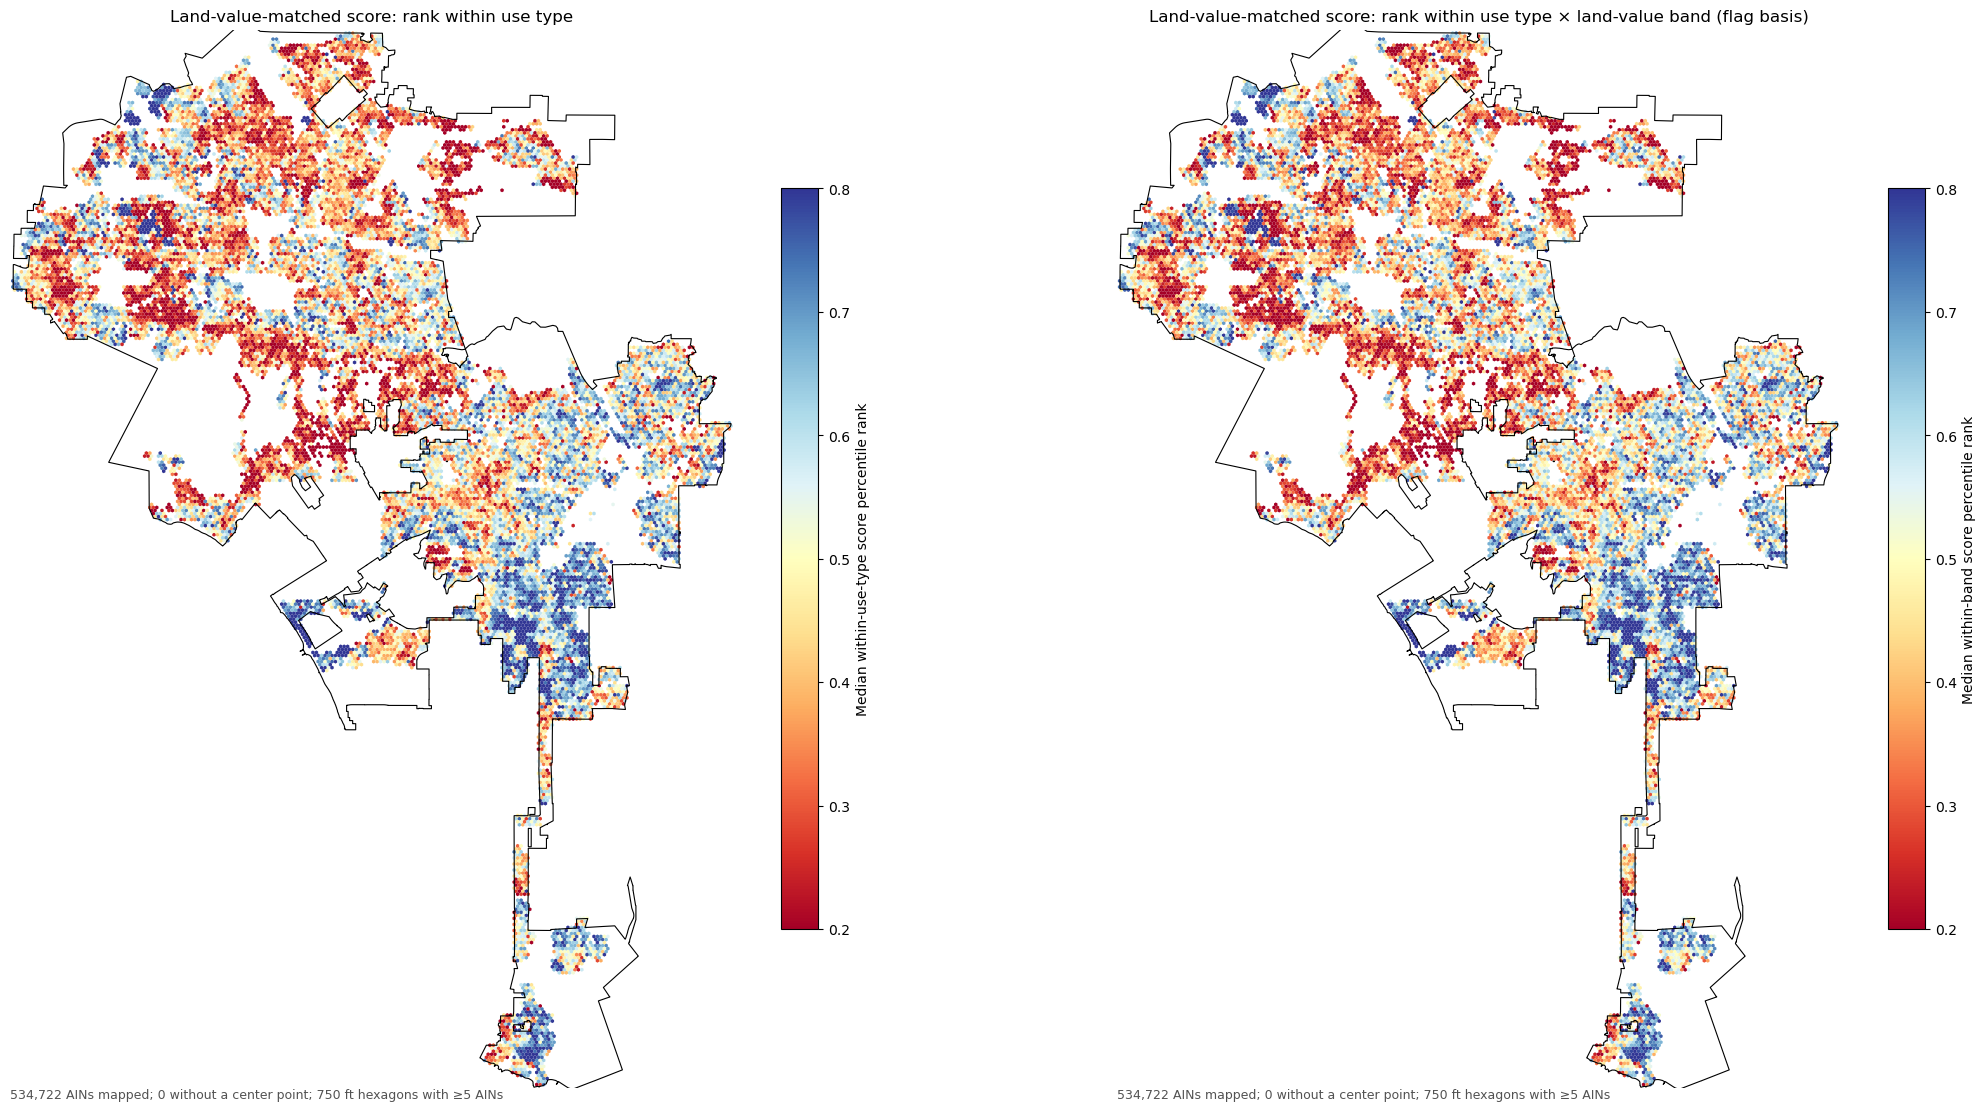

In [15]:
# Same colours as the other Method 3 maps: red leans least UDU-like.
lv_unlabeled = method3_lv_features.loc[~method3_lv_features['is_known_udu']]
boundary = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson').to_crs(AIN_POINT_CRS)

fig, axes = plt.subplots(1, 2, figsize=(22, 11), constrained_layout=True)
for ax, column, title, label in [
    (axes[0], 'method3_score_pct_rank_by_use_type',
     'Land-value-matched score: rank within use type',
     'Median within-use-type score percentile rank'),
    (axes[1], 'method3_score_pct_rank_by_band',
     'Land-value-matched score: rank within use type × land-value band (flag basis)',
     'Median within-band score percentile rank'),
]:
    plot_ain_hexbin(
        lv_unlabeled, column, ax=ax, cmap='RdYlBu', vmin=0.2, vmax=0.8,
        hex_width_ft=750, title=title, colorbar_label=label,
    )
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    boundary.boundary.plot(ax=ax, color='k', linewidth=0.8)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
plt.show()

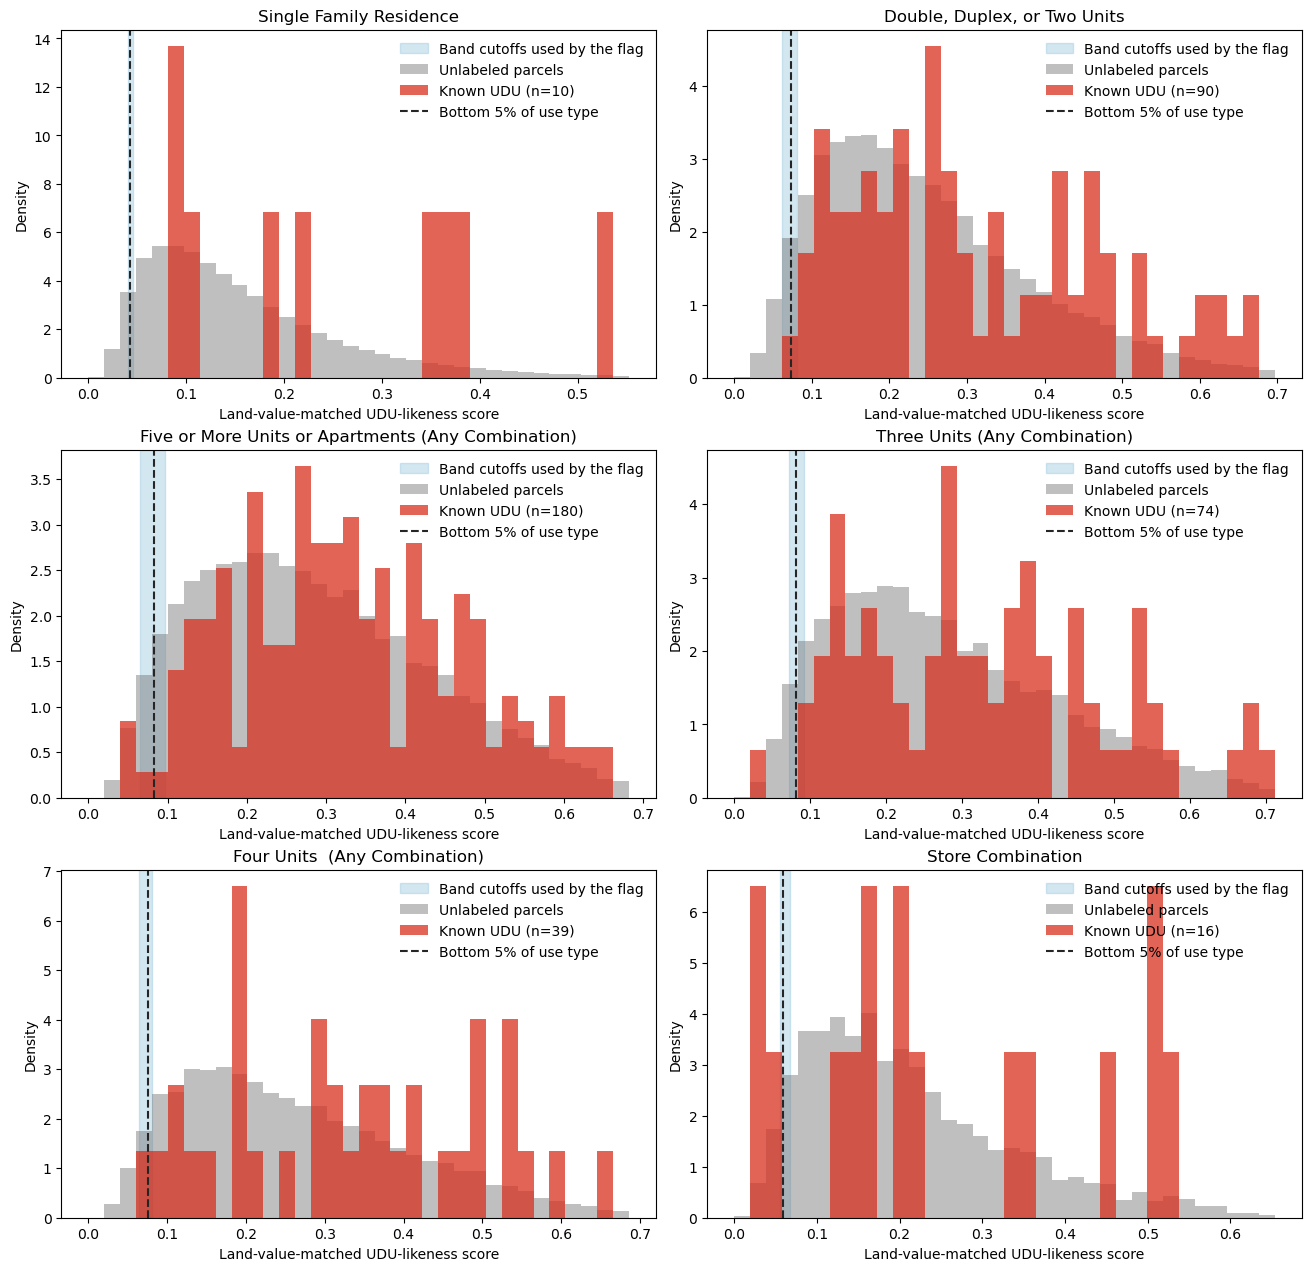

In [16]:
# Score distributions by use type, as in the baseline diagnostics. method3_udu_score
# here is method3_landvalue_udu_score in method3_ain_scores. The flag cuts within
# use type × land-value band, so the shaded span shows the range of those band
# cutoffs (bands 1–10); the dashed line is the single use-type cutoff for reference.
use_types = method3_lv_features['SpecificUseType'].value_counts().index.tolist()
ncols = 2
nrows = int(np.ceil(len(use_types) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.2 * nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, use_types):
    group = method3_lv_features.loc[method3_lv_features['SpecificUseType'].eq(use_type)]
    other = group.loc[~group['is_known_udu'], 'method3_udu_score']
    known = group.loc[group['is_known_udu'], 'method3_udu_score']
    band_cutoffs = (
        group.loc[group['method3_lv_band'].gt(0)]
        .groupby('method3_lv_band')['method3_udu_score'].quantile(METHOD3_PERCENTILE)
    )
    bins = np.linspace(0, max(group['method3_udu_score'].quantile(0.995), 1e-6), 35)
    ax.axvspan(
        band_cutoffs.min(), band_cutoffs.max(), color='#9ecae1', alpha=0.45,
        label='Band cutoffs used by the flag',
    )
    ax.hist(other, bins=bins, density=True, alpha=0.45, color='#737373', label='Unlabeled parcels')
    ax.hist(known, bins=bins, density=True, alpha=0.75, color='#d7301f', label=f'Known UDU (n={len(known):,})')
    ax.axvline(
        group['method3_udu_score'].quantile(METHOD3_PERCENTILE),
        color='#252525', linestyle='--', label='Bottom 5% of use type',
    )
    ax.set_title(use_type, wrap=True)
    ax.set_xlabel('Land-value-matched UDU-likeness score')
    ax.set_ylabel('Density')
    ax.legend(frameon=False)
for ax in axes[len(use_types):]:
    ax.remove()
plt.show()

,feature,mean_abs_shap,feature_family,tract_matched_rank
rank,,,,
1,land_value_share,0.1433,assessor and parcel–building relations,4
2,age_2017,0.0946,assessor and parcel–building relations,11
3,parcel.circularity,0.0830,parcel shape and open space,23
4,renovation_gap,0.0702,assessor and parcel–building relations,6
5,bathrooms_per_unit,0.0700,assessor and parcel–building relations,12
6,open_space_per_building,0.0671,parcel shape and open space,20
7,bedrooms_per_unit,0.0658,assessor and parcel–building relations,17
8,sqft_per_unit,0.0642,assessor and parcel–building relations,8
9,bldg.area.std,0.0622,building morphology,39


,land-value-matched,tract-matched
share of mean |SHAP|,,
building morphology,0.442,0.455
assessor and parcel–building relations,0.341,0.341
parcel shape and open space,0.183,0.142
administrative and assessor history,0.032,0.028
use type indicators,0.002,0.003
TCAC opportunity context,NaN,0.031


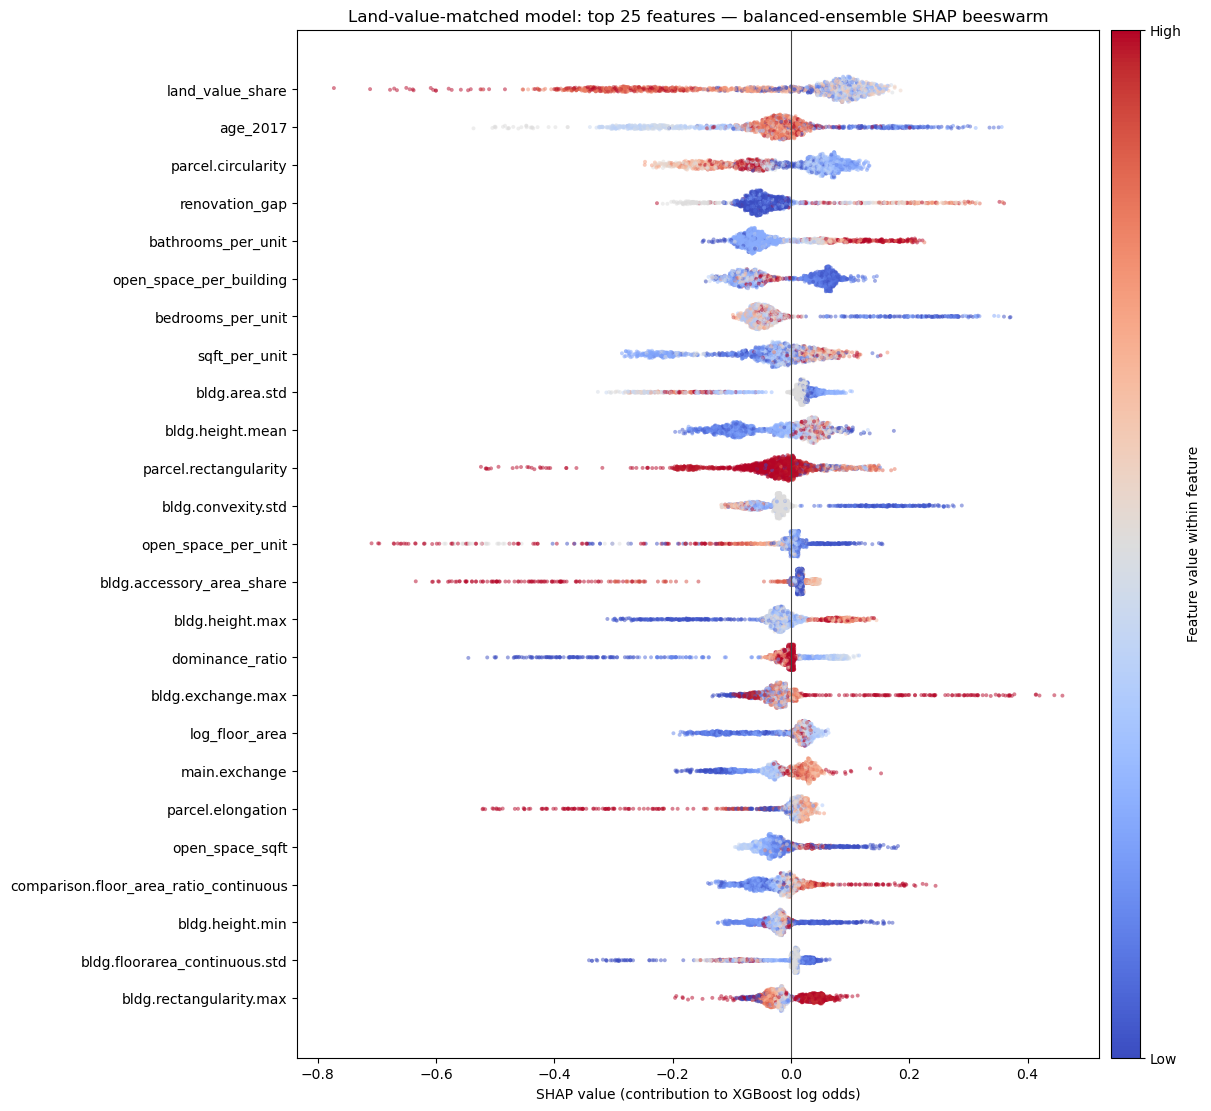

In [17]:
def build_landvalue_shap_summary(data, feature_columns):
    """SHAP values from land-value-matched bags fitted on every eligible parcel."""
    X = build_model_matrix(data, feature_columns)
    y = data['is_known_udu'].astype(int).to_numpy()
    all_rows = np.arange(len(data))
    explanation_pool = sample_matched_bags(
        data, all_rows, [RANDOM_STATE + 290_000], LV_MATCH_KEYS
    )[0]
    rng = np.random.default_rng(RANDOM_STATE + 291_000)
    explanation_rows = (
        rng.choice(explanation_pool, SHAP_SAMPLE_SIZE, replace=False)
        if len(explanation_pool) > SHAP_SAMPLE_SIZE else explanation_pool
    )
    explanation = X.iloc[explanation_rows].copy()
    dmatrix = xgb.DMatrix(explanation, feature_names=list(X.columns))
    contributions = np.zeros(explanation.shape, dtype='float64')
    seeds = [RANDOM_STATE + 292_000 + bag for bag in range(N_BALANCED_BAGS)]
    for seed, rows in zip(seeds, sample_matched_bags(data, all_rows, seeds, LV_MATCH_KEYS)):
        model = make_method3_model(seed, y[rows])
        model.fit(X.iloc[rows], y[rows])
        contributions += model.get_booster().predict(dmatrix, pred_contribs=True)[:, :-1]
    contributions /= N_BALANCED_BAGS
    importance = (
        pd.DataFrame({
            'feature': X.columns,
            'mean_abs_shap': np.mean(np.abs(contributions), axis=0),
        })
        .sort_values('mean_abs_shap', ascending=False)
        .reset_index(drop=True)
    )
    return explanation.reset_index(drop=True), contributions, importance

(
    method3_lv_shap_feature_values, method3_lv_shap_values, method3_lv_shap_importance,
) = build_landvalue_shap_summary(method3_input, LV_MODEL_FEATURES)

tract_matched_rank = pd.Series(
    np.arange(1, len(method3_shap_importance) + 1),
    index=method3_shap_importance['feature'],
)
display(
    method3_lv_shap_importance.head(SHAP_TOP_N)
    .assign(
        rank=lambda frame: np.arange(1, len(frame) + 1),
        feature_family=lambda frame: frame['feature'].map(feature_family),
        tract_matched_rank=lambda frame: frame['feature'].map(tract_matched_rank),
    )
    .set_index('rank')
    .round({'mean_abs_shap': 4})
)
family_share = pd.DataFrame({
    'land-value-matched': method3_lv_shap_importance.groupby(
        method3_lv_shap_importance['feature'].map(feature_family)
    )['mean_abs_shap'].sum(),
    'tract-matched': method3_shap_importance.groupby(
        method3_shap_importance['feature'].map(feature_family)
    )['mean_abs_shap'].sum(),
})
display(
    (family_share / family_share.sum())
    .sort_values('land-value-matched', ascending=False)
    .rename_axis('share of mean |SHAP|')
    .round(3)
)
plot_shap_beeswarm(
    method3_lv_shap_feature_values, method3_lv_shap_values,
    method3_lv_shap_importance, top_n=SHAP_TOP_N,
    title=f'Land-value-matched model: top {SHAP_TOP_N} features — balanced-ensemble SHAP beeswarm',
)

## Final AIN-level scores

`method3_ain_scores` holds one row per eligible AIN with the tract-matched baseline, regularized and land-value-matched scores, ranks and flags side by side. The land-value model also carries its band and within-band rank, which its flag uses. The final `method3_udu_score`, `method3_score_pct_rank_by_use_type` and `method3_potential_nonudu` columns, and the standardized `method3_output` (`AIN`, `method3_potential_nonudu`), come from the model named in `METHOD3_FINAL_MODEL`. The baseline stays the default until another model is preferred on the comparisons above.

In [18]:
METHOD3_FINAL_MODEL = 'baseline'  # 'baseline', 'regularized' or 'landvalue'

METHOD3_SCORE_COLUMNS = {
    'method3_udu_score': 'udu_score',
    'method3_score_pct_rank_by_use_type': 'score_pct_rank_by_use_type',
    'method3_potential_nonudu': 'potential_nonudu',
}

def model_ain_scores(features, model):
    return features[['AIN', *METHOD3_SCORE_COLUMNS]].rename(columns={
        column: f'method3_{model}_{suffix}'
        for column, suffix in METHOD3_SCORE_COLUMNS.items()
    })

if METHOD3_FINAL_MODEL not in {'baseline', 'regularized', 'landvalue'}:
    raise ValueError(f'Unknown METHOD3_FINAL_MODEL: {METHOD3_FINAL_MODEL!r}')

method3_ain_scores = (
    method3_features[[
        'AIN', 'SpecificUseType', 'is_known_udu',
        'method3_in_training_geography', 'GEOID_TRACT', 'method3_score_method',
    ]]
    .merge(model_ain_scores(method3_features, 'baseline'), on='AIN', validate='one_to_one')
    .merge(model_ain_scores(method3_reg_features, 'regularized'), on='AIN', validate='one_to_one')
    .merge(model_ain_scores(method3_lv_features, 'landvalue'), on='AIN', validate='one_to_one')
    .merge(
        method3_lv_features[['AIN', 'method3_lv_band', 'method3_score_pct_rank_by_band']]
        .rename(columns={
            'method3_lv_band': 'method3_landvalue_band',
            'method3_score_pct_rank_by_band': 'method3_landvalue_score_pct_rank_by_band',
        }),
        on='AIN', validate='one_to_one',
    )
)
for column, suffix in METHOD3_SCORE_COLUMNS.items():
    method3_ain_scores[column] = method3_ain_scores[f'method3_{METHOD3_FINAL_MODEL}_{suffix}']
method3_ain_scores['method3_final_model'] = METHOD3_FINAL_MODEL
method3_ain_scores['method3_percentile_cutoff'] = float(METHOD3_PERCENTILE)
method3_ain_scores = method3_ain_scores.sort_values('AIN').reset_index(drop=True)
method3_output = method3_ain_scores[['AIN', 'method3_potential_nonudu']].copy()

display(pd.Series({
    'final model': METHOD3_FINAL_MODEL,
    'output AINs': len(method3_output),
    'final potential non-UDU AINs': int(method3_output['method3_potential_nonudu'].sum()),
    'final potential non-UDU share': method3_output['method3_potential_nonudu'].mean(),
    'flagged by baseline': int(method3_ain_scores['method3_baseline_potential_nonudu'].sum()),
    'flagged by regularized': int(method3_ain_scores['method3_regularized_potential_nonudu'].sum()),
    'flagged by land-value model': int(method3_ain_scores['method3_landvalue_potential_nonudu'].sum()),
    'flagged by baseline and regularized': int((
        method3_ain_scores['method3_baseline_potential_nonudu']
        & method3_ain_scores['method3_regularized_potential_nonudu']
    ).sum()),
    'known UDU flagged (should be 0)': int((
        method3_ain_scores['method3_potential_nonudu']
        & method3_ain_scores['is_known_udu']
    ).sum()),
}, name='value').to_frame())
display(method3_ain_scores.head())
display(method3_output.head())

# Deliberately not saved during method development. When finalized:
# output_path = CITY_OUTPUT / 'method3_potential_nonudu_2017.parquet'
# output_path.parent.mkdir(parents=True, exist_ok=True)
# method3_output.to_parquet(output_path, index=False)

,value
final model,baseline
output AINs,535131
final potential non-UDU AINs,26746
final potential non-UDU share,0.04998
flagged by baseline,26746
flagged by regularized,26746
flagged by land-value model,26723
flagged by baseline and regularized,21202
known UDU flagged (should be 0),0


,AIN,SpecificUseType,is_known_udu,method3_in_training_geography,GEOID_TRACT,method3_score_method,method3_baseline_udu_score,method3_baseline_score_pct_rank_by_use_type,method3_baseline_potential_nonudu,method3_regularized_udu_score,...,method3_landvalue_udu_score,method3_landvalue_score_pct_rank_by_use_type,method3_landvalue_potential_nonudu,method3_landvalue_band,method3_landvalue_score_pct_rank_by_band,method3_udu_score,method3_score_pct_rank_by_use_type,method3_potential_nonudu,method3_final_model,method3_percentile_cutoff
0,2004001003,Single Family Residence,False,False,NaN,fold_ensemble_application,0.084885,0.154909,False,0.181972,...,0.027296,0.009359,True,8,0.013003,0.084885,0.154909,False,baseline,0.05
1,2004001004,Single Family Residence,False,False,NaN,fold_ensemble_application,0.429744,0.944081,False,0.530635,...,0.263454,0.860817,False,6,0.851504,0.429744,0.944081,False,baseline,0.05
2,2004001005,Single Family Residence,False,False,NaN,fold_ensemble_application,0.348032,0.863445,False,0.443215,...,0.202676,0.745349,False,3,0.769122,0.348032,0.863445,False,baseline,0.05
3,2004001008,Single Family Residence,False,False,NaN,fold_ensemble_application,0.080636,0.137957,False,0.176041,...,0.039397,0.040167,True,3,0.034668,0.080636,0.137957,False,baseline,0.05
4,2004001009,Single Family Residence,False,False,NaN,fold_ensemble_application,0.291334,0.775950,False,0.453499,...,0.159642,0.613202,False,2,0.630358,0.291334,0.775950,False,baseline,0.05


,AIN,method3_potential_nonudu
0,2004001003,False
1,2004001004,False
2,2004001005,False
3,2004001008,False
4,2004001009,False


In [19]:
# AIN-level scores for the cross-method comparison in notebook 04. This is an
# intermediate file, separate from the final output above.
METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
METHOD_SCORES_DIR.mkdir(parents=True, exist_ok=True)
method3_ain_scores.to_parquet(METHOD_SCORES_DIR / 'method3_scores_2017.parquet', index=False)
print(f'Saved {len(method3_ain_scores):,} AIN rows to {METHOD_SCORES_DIR / "method3_scores_2017.parquet"}')

Saved 535,131 AIN rows to /Users/adamswietek/Documents/NDSC_HiddenHousing/data/02_intermediate/method_scores/method3_scores_2017.parquet


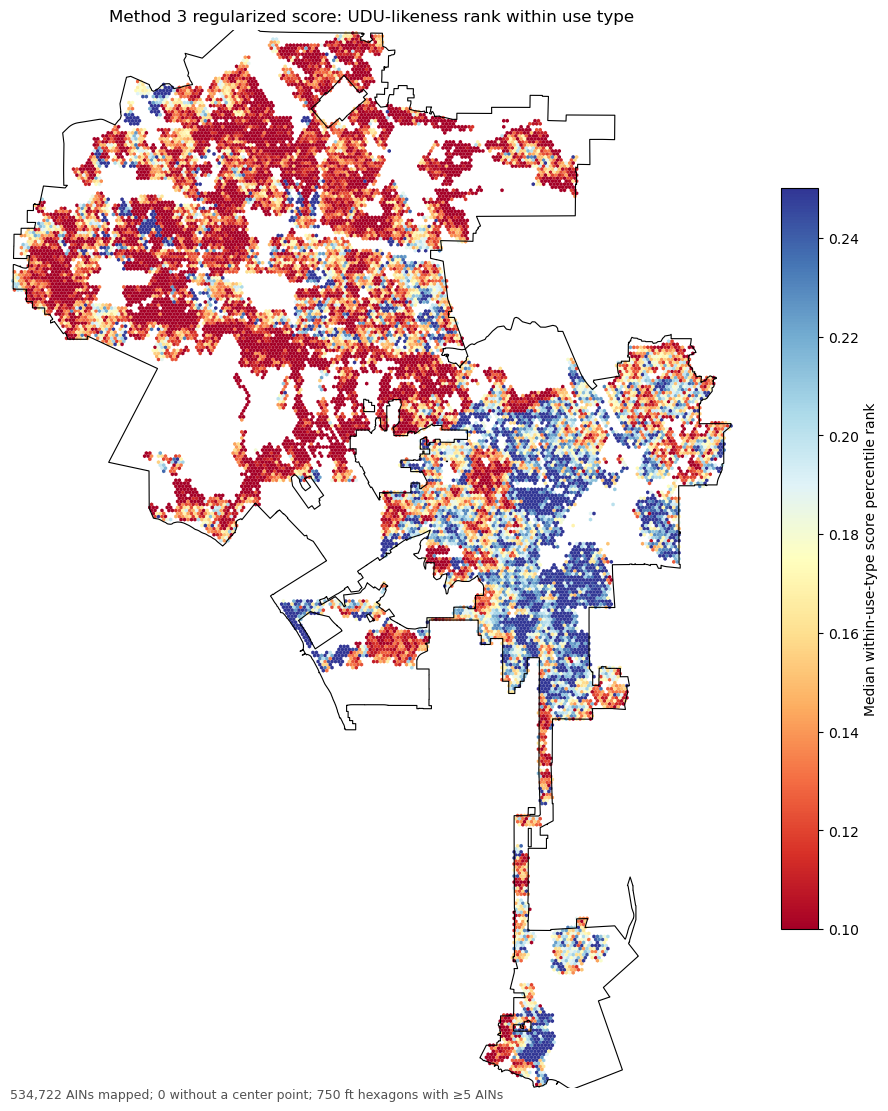

In [20]:
# Same scale and colours as the baseline map above: red leans least UDU-like.
regularized_unlabeled = method3_ain_scores.loc[~method3_ain_scores['is_known_udu']]

fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)
plot_ain_hexbin(
    regularized_unlabeled, 'method3_landvalue_udu_score', ax=ax,
    cmap='RdYlBu', 
    vmin=0.1, vmax=0.25, 
    hex_width_ft=750,
    title='Method 3 regularized score: UDU-likeness rank within use type',
    colorbar_label='Median within-use-type score percentile rank',
)
# GeoJSON is WGS84; the hexbins are in EPSG:2229 feet.
lac = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
lac.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()

## Where the known UDUs are

Every AIN in the current UDU report, located by its assessor center point. The left map marks which reports are in the Method 3 eligible set; the others fall outside it, for example multi-AIN sites or unsupported use types. The right map counts reports per 1-mile hexagon. Reports cluster where people file them, which is why the model samples unlabeled parcels from the same tracts as known UDUs.

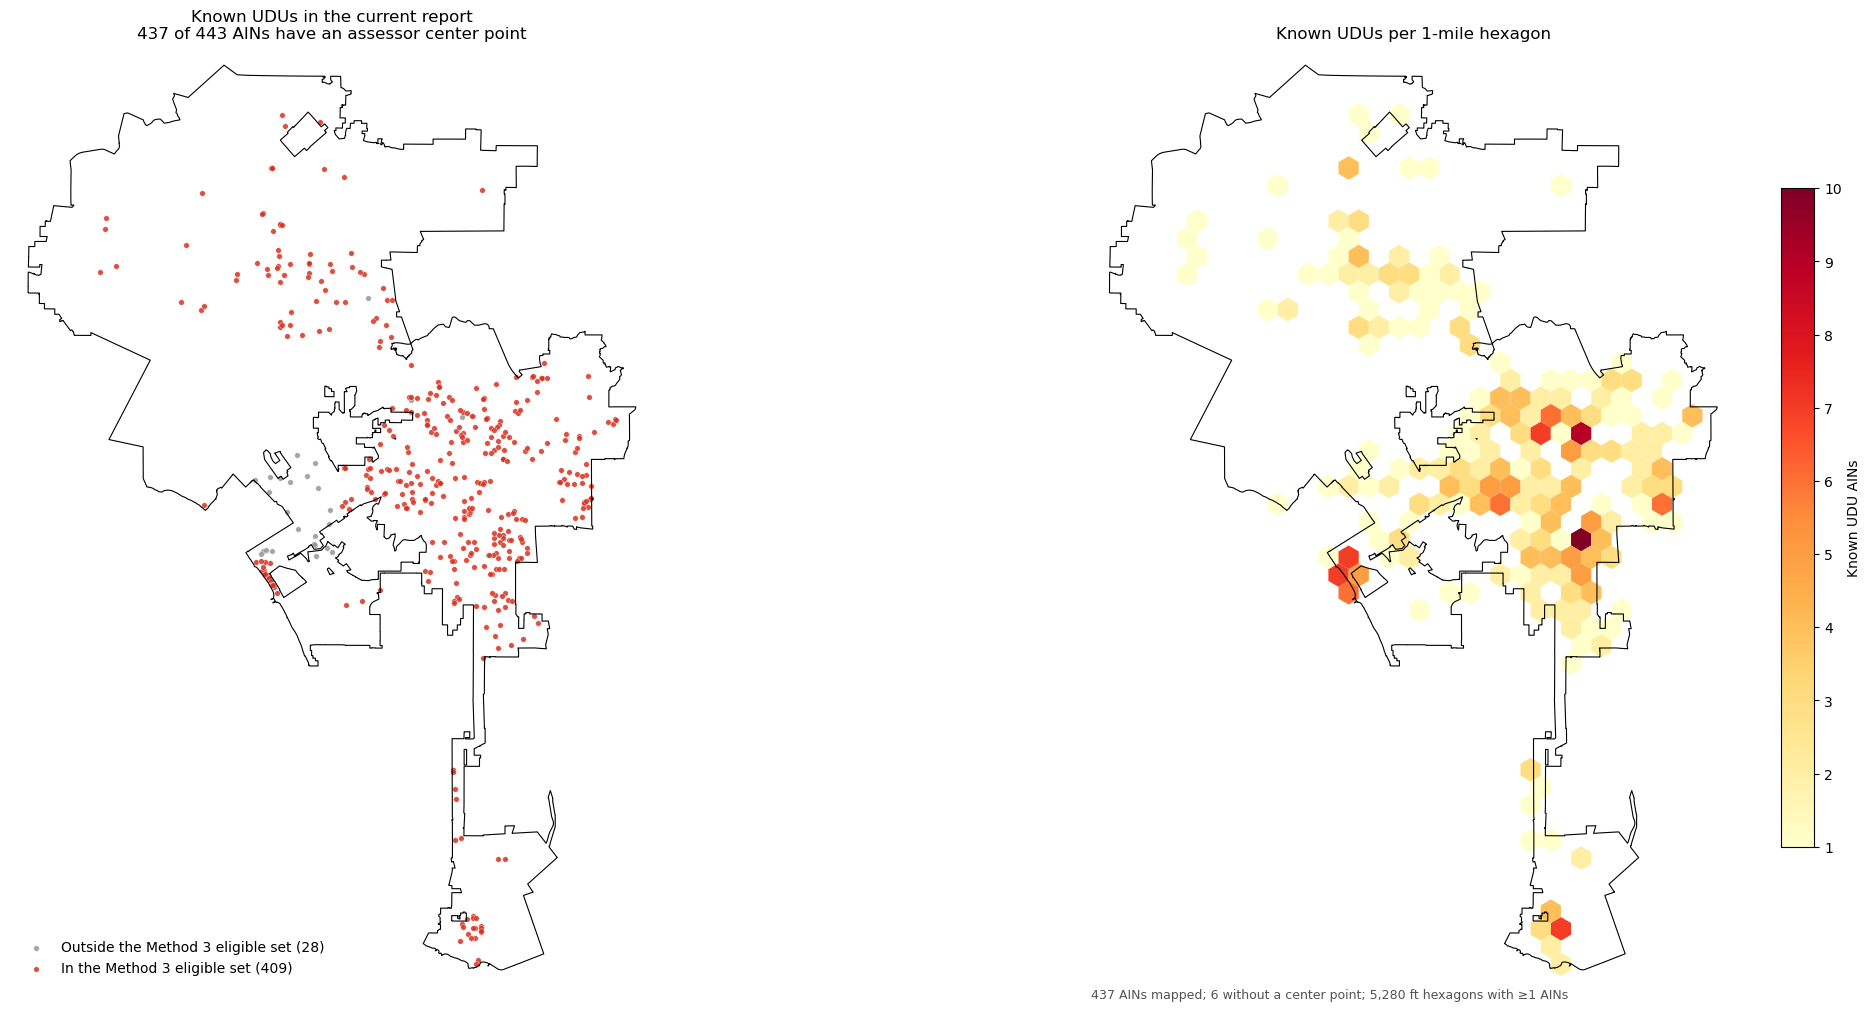

In [21]:
from src.viz import load_ain_points

udu_points = (
    pd.DataFrame({'AIN': sorted(known_udu_ains)})
    .merge(load_ain_points(), on='AIN', how='left', validate='one_to_one')
)
udu_points['method3_eligible'] = udu_points['AIN'].isin(set(method3_ain_scores['AIN']))
located = udu_points.loc[udu_points['x'].notna()]

city_boundary = gpd.read_file(
    PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson'
).to_crs(AIN_POINT_CRS)
minx, miny, maxx, maxy = city_boundary.total_bounds
pad = 0.02 * max(maxx - minx, maxy - miny)

fig, axes = plt.subplots(1, 2, figsize=(20, 10), constrained_layout=True)
ax = axes[0]
for eligible, color, label in [
    (False, '#969696', 'Outside the Method 3 eligible set'),
    (True, '#d7301f', 'In the Method 3 eligible set'),
]:
    subset = located.loc[located['method3_eligible'].eq(eligible)]
    ax.scatter(
        subset['x'], subset['y'], s=16, color=color, alpha=0.85,
        edgecolor='white', linewidth=0.3, label=f'{label} ({len(subset):,})',
    )
ax.set_title(
    f'Known UDUs in the current report\n'
    f'{len(located):,} of {len(udu_points):,} AINs have an assessor center point'
)
ax.legend(frameon=False, loc='lower left')

plot_ain_hexbin(
    udu_points.assign(known_udu=1), 'known_udu', ax=axes[1],
    reduce_function=np.sum, min_count=1, hex_width_ft=5280,
    cmap='YlOrRd', vmin=1,
    title='Known UDUs per 1-mile hexagon', colorbar_label='Known UDU AINs',
)
for ax in axes:
    city_boundary.boundary.plot(ax=ax, color='k', linewidth=0.8)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_aspect('equal')
    ax.set_axis_off()
plt.show()